# V4 · Zeilenweise Erklärung

Diese Lernfassung erläutert jede nichtleere Codezeile der V4 mit einem Kommentar direkt darüber. Die Angaben „V4, Zeile …“ beziehen sich jeweils auf die ursprüngliche Codezelle. Leerzeilen gliedern den Code; bestehende Kommentare bleiben erhalten. Die gespeicherten Tabellen und Diagramme stammen aus dem geprüften V4-Lauf. Die Modellrechnung ist identisch mit V4.


# Kostenorientierte Klassifikation von Maschinenausfällen

**Gruppenarbeit Classification · Business Intelligence · WiSe 2026/27**  
Technische Hochschule Mannheim · Gruppe: [Gruppenname] · Mitglieder: [Jannika Julia Heckmann, Felix Bauer, Anita Kopp, Jason Neufeld]

Ziel ist die Vorhersage von Maschinenfehlschlägen unter der Kostenfunktion **FP + 6 × FN**. Diese V4 greift die Struktur der bereitgestellten Data-Desperados-Unterlagen auf: Datenverständnis, physikalische Merkmale, nachvollziehbare Baumregeln, Kostenvergleich und Challenge-Prognose. Die Modellparameter werden aus den Trainingsfalten der aktuellen Aufgabenstellung gelernt. Die Ergebnisse der Vorlage werden durch eigene Berechnungen überprüft.

**Reproduktion.** Das Notebook enthält den vollständigen Modellcode und verwendet die bereitgestellten Dateien modeling.csv und challenge.csv. Die Konfiguration und der Gruppenname für den CSV-Export stehen in der ersten Codezelle. Für die Ausführung werden NumPy, pandas, scikit-learn und Matplotlib benötigt.

In [1]:
# V4, Zeile 1: Lädt reguläre Ausdrücke; damit wird später der Gruppenname geprüft.
import re
# V4, Zeile 2: Lädt Path, um Datei- und Ordnerpfade zusammenzusetzen.
from pathlib import Path

# V4, Zeile 4: Lädt NumPy unter dem Kurznamen np für Zahlenfelder und Berechnungen.
import numpy as np
# V4, Zeile 5: Lädt pandas unter dem Kurznamen pd für Tabellen und CSV-Dateien.
import pandas as pd
# V4, Zeile 6: Lädt die Begrenzung paralleler Rechenthreads, damit der Vergleich den Rechner nicht überlastet.
from threadpoolctl import threadpool_limits
# V4, Zeile 7: Lädt clone; jede Trainingsfalte bekommt damit ein frisches Modell mit denselben Einstellungen.
from sklearn.base import clone
# V4, Zeile 8: Lädt die beiden Ensembleverfahren Random Forest und Histogram Gradient Boosting.
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
# V4, Zeile 9: Lädt den Klassifikator für die k nächsten Nachbarn.
from sklearn.neighbors import KNeighborsClassifier
# V4, Zeile 10: Lädt den Entscheidungsbaum sowie die Funktion für seine grafische Darstellung.
from sklearn.tree import DecisionTreeClassifier, plot_tree
# V4, Zeile 11: Lädt die logistische Regression zur Schätzung von Ausfallwahrscheinlichkeiten.
from sklearn.linear_model import LogisticRegression
# V4, Zeile 12: Lädt die Konfusionsmatrix, die richtige und falsche Vorhersagen zählt.
from sklearn.metrics import confusion_matrix
# V4, Zeile 13: Lädt Kreuzvalidierung mit möglichst gleichen Klassenanteilen in allen Falten.
from sklearn.model_selection import StratifiedKFold
# V4, Zeile 14: Lädt make_pipeline, um Aufbereitung und Klassifikator in einer Trainingskette zu verbinden.
from sklearn.pipeline import make_pipeline
# V4, Zeile 15: Lädt den StandardScaler; er lernt Mittelwert und Streuung ausschließlich beim Fit.
from sklearn.preprocessing import StandardScaler

# V4, Zeile 17: Setzt den Gruppennamen für den späteren Dateinamen; diesen Platzhalter vor der Abgabe ersetzen.
GRUPPENNAME = "GRUPPENNAME"
# V4, Zeile 18: Verwendet zunächst das Arbeitsverzeichnis des Notebook-Kernels als Datenordner.
DATENORDNER = Path(".") 
# V4, Zeile 19: Prüft, ob modeling.csv im eingestellten Datenordner fehlt.
if not (DATENORDNER / "modeling.csv").is_file():
    # V4, Zeile 20: Weicht dann auf den persönlichen Download-Ordner aus.
    DATENORDNER = Path.home() / "Downloads"
# V4, Zeile 21: Legt results als Ausgabeordner relativ zum Arbeitsverzeichnis fest.
AUSGABEORDNER = Path("results")

# V4, Zeile 23: Speichert den exakten Namen der binären Zielspalte.
TARGET = "Machine failure"
# V4, Zeile 24: Beginnt die Liste der Eingangsspalten mit Typ und den beiden Temperaturen.
FEATURES = ["Type", "Air temperature [K]", "Process temperature [K]",
            # V4, Zeile 25: Ergänzt Drehzahl, Drehmoment und Werkzeugstandzeit und schließt die Liste.
            "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
# V4, Zeile 26: Kodiert die Produktvarianten als geordnete Stufen 0, 1 und 2.
TYP = {"L": 0, "M": 1, "H": 2}
# V4, Zeile 27: Setzt die Kosten eines übersehenen Ausfalls auf sechs Fehlalarmeinheiten.
KOSTEN_FN = 6
# V4, Zeile 28: Leitet aus 1−p ≤ 6p die Alarmschwelle 1/7 für die Verschleißstufe ab.
SCHWELLE = 1 / (1 + KOSTEN_FN)
# V4, Zeile 29: Legt fünf reproduzierbare Zufallsstarts für fünf unterschiedliche Faltenaufteilungen fest.
SEEDS = (2006, 2026, 2007, 888, 1024)

## 1 · Explorative Datenanalyse

Der beschriftete Datensatz umfasst **8.000 Produktionsvorgänge**, davon **271 Ausfälle (3,39 %)**. Geprüft werden das Eingabeschema, die Gültigkeit der Sensorwerte, die Zielklassen und doppelte Merkmalszeilen. Die folgende Auswertung beschreibt die Ausfallhäufigkeit nach Produktvariante und die Verteilung der numerischen Merkmale. Extreme Messwerte bleiben als potenziell relevante Ausfallsignale erhalten.

In [2]:
# V4, Zeile 1: Definiert den CSV-Import; mit_labels bestimmt, ob die Zielspalte erwartet wird.
def csv_lesen(pfad, mit_labels=False):
    # V4, Zeile 2: Prüft vor dem Einlesen, ob die Datei vorhanden ist.
    if not pfad.is_file():
        # V4, Zeile 3: Bricht mit einer verständlichen Pfadmeldung ab, wenn die Datei fehlt.
        raise FileNotFoundError(f"{pfad} fehlt. Prüfe DATENORDNER in der ersten Zelle.")
    # V4, Zeile 4: Liest die Tabelle so ein, dass Float64-Werte beim Zurückwandeln möglichst erhalten bleiben.
    daten = pd.read_csv(pfad, float_precision="round_trip")
    # V4, Zeile 5: Erwartet bei Trainingsdaten zusätzlich die Zielspalte, bei der Challenge nur die Merkmale.
    erwartet = FEATURES + ([TARGET] if mit_labels else [])
    # V4, Zeile 6: Prüft auf eine leere Tabelle und auf fehlende oder zusätzliche Spalten.
    if daten.empty or set(daten.columns) != set(erwartet):
        # V4, Zeile 7: Bricht bei einem falschen Eingabeschema ab und nennt die erwarteten Spalten.
        raise ValueError(f"{pfad}: Erwartete Spalten: {erwartet}")
    # V4, Zeile 8: Prüft, ob alle Typen bekannt und alle numerischen Sensorwerte endlich sind; fehlende Werte und Unendlichkeiten werden so erkannt.
    if not daten["Type"].isin(TYP).all() or not np.isfinite(daten[FEATURES[1:]].to_numpy(float)).all():
        # V4, Zeile 9: Bricht bei ungültigen Typen oder Messwerten ab.
        raise ValueError(f"{pfad}: Ungültige Messwerte oder Produktvarianten.")
    # V4, Zeile 10: Prüft bei beschrifteten Daten, ob die Zielwerte genau die beiden Klassen 0 und 1 enthalten.
    if mit_labels and set(daten[TARGET].unique()) != {0, 1}:
        # V4, Zeile 11: Bricht ab, wenn eine Zielklasse fehlt oder ein ungültiges Label vorkommt.
        raise ValueError(f"{pfad}: Die Zielspalte muss beide Klassen 0 und 1 enthalten.")
    # V4, Zeile 12: Gibt die geprüfte Tabelle an den aufrufenden Code zurück.
    return daten

# V4, Zeile 14: Lädt ausschließlich die beschriftete modeling.csv für Analyse und Modellierung.
daten = csv_lesen(DATENORDNER / "modeling.csv", mit_labels=True)
# V4, Zeile 15: Trennt die sechs Eingabespalten X von den ganzzahligen Zielwerten y.
X, y = daten[FEATURES], daten[TARGET].to_numpy(dtype=int)
# V4, Zeile 16: Zeigt Datenumfang, Ausfallzahl, Ausfallquote und doppelte Merkmalszeilen an.
print(f"{len(y)} Vorgänge | {y.sum()} Ausfälle ({y.mean():.2%}) | {X.duplicated().sum()} doppelte Merkmalszeilen")
# V4, Zeile 17: Zählt je Produkttyp die Vorgänge und summiert die Einsen als Ausfälle.
varianten = daten.groupby("Type")[TARGET].agg(Vorgänge="size", Ausfälle="sum")
# V4, Zeile 18: Berechnet die Ausfallquote je Typ in Prozent und zeigt die Tabelle mit zwei Nachkommastellen.
display(varianten.assign(Ausfallquote_Prozent=100 * varianten["Ausfälle"] / varianten["Vorgänge"]).round(2))
# V4, Zeile 19: Zeigt Anzahl, Mittelwert, Streuung, Quantile und Extremwerte der numerischen Merkmale.
display(X[FEATURES[1:]].describe().round(2))

8000 Vorgänge | 271 Ausfälle (3.39%) | 0 doppelte Merkmalszeilen


,Vorgänge,Ausfälle,Ausfallquote_Prozent
Type,,,
H,795,18,2.26
L,4808,184,3.83
M,2397,69,2.88


,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
count,8000.00,8000.00,8000.00,8000.00,8000.00
mean,300.00,310.00,1538.33,40.00,107.84
std,1.99,1.48,178.48,9.95,63.65
min,295.30,305.70,1181.00,3.80,0.00
25%,298.30,308.80,1423.00,33.20,53.00
50%,300.10,310.10,1503.00,40.10,108.00
75%,301.50,311.10,1611.00,46.70,162.00
max,304.50,313.80,2886.00,76.60,253.00


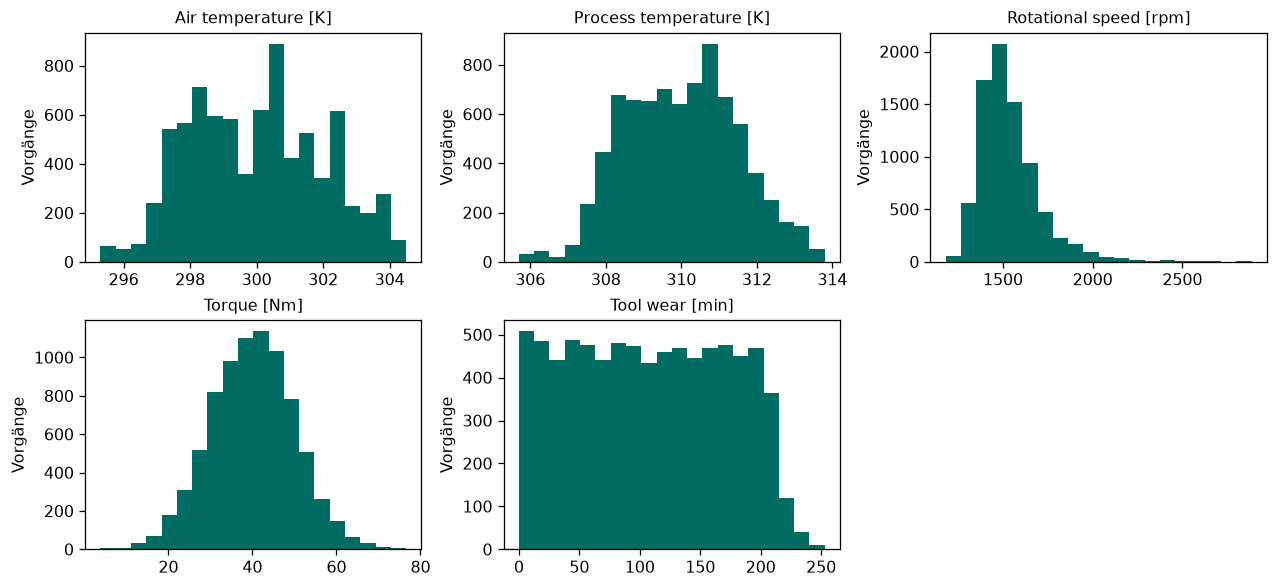

In [3]:
# V4, Zeile 1: Beginnt einen Importversuch, dessen fehlendes Paket gezielt behandelt werden kann.
try:
    # V4, Zeile 2: Lädt die Matplotlib-Figurklasse, mit der die Diagramme erzeugt werden.
    from matplotlib.figure import Figure
# V4, Zeile 3: Fängt einen fehlgeschlagenen Paketimport ab und speichert die Fehlerinformation in error.
except ModuleNotFoundError as error:
    # V4, Zeile 4: Prüft, ob ein anderes Paket als matplotlib fehlt.
    if error.name != "matplotlib":
        # V4, Zeile 5: Reicht diesen anderen Importfehler weiter, damit seine Ursache sichtbar bleibt.
        raise
    # V4, Zeile 6: Kennzeichnet mit None, dass in diesem Lauf keine neuen Diagramme gezeichnet werden können.
    Figure = None

# V4, Zeile 8: Definiert eine Hilfsfunktion, die eine fertige Figur im Notebook anzeigt.
def diagramm_anzeigen(fig):
    # V4, Zeile 9: Lädt einen Byte-Puffer, um die Grafik ohne separate Bilddatei zwischenzuspeichern.
    from io import BytesIO
    # V4, Zeile 10: Lädt die Bildanzeige für die Notebook-Ausgabe.
    from IPython.display import Image

    # V4, Zeile 12: Erstellt den leeren Speicherpuffer für das PNG-Bild.
    bild = BytesIO()
    # V4, Zeile 13: Schreibt die Figur als PNG mit 115 Punkten pro Zoll in den Puffer und beschneidet leeren Rand.
    fig.savefig(bild, format="png", dpi=115, bbox_inches="tight")
    # V4, Zeile 14: Liest die gespeicherten Bildbytes und zeigt sie in der aktuellen Ausgabezelle an.
    display(Image(data=bild.getvalue()))

# V4, Zeile 16: Prüft, ob Matplotlib beim Import nicht verfügbar war.
if Figure is None:
    # V4, Zeile 17: Gibt dann den Installationshinweis aus. Die nachfolgenden Berechnungen können weiterlaufen.
    print("Für neu gerenderte Diagramme: %pip install matplotlib. Die Tabellen bleiben verfügbar.")
# V4, Zeile 18: Beginnt den Zeichenblock für den Fall, dass Matplotlib verfügbar ist.
else:
    # V4, Zeile 19: Erzeugt eine 11 × 5 Zoll große Figur mit automatisch angepassten Abständen.
    fig = Figure(figsize=(11, 5), layout="constrained")
    # V4, Zeile 20: Teilt die Figur in zwei Zeilen mit jeweils drei Zeichenflächen auf.
    axes = fig.subplots(2, 3)
    # V4, Zeile 21: Ordnet den fünf numerischen Sensorwerten nacheinander eine Zeichenfläche zu; Type wird übersprungen.
    for ax, spalte in zip(axes.flat, FEATURES[1:]):
        # V4, Zeile 22: Zeichnet das Histogramm dieser Spalte mit 20 Werteintervallen in Dunkelgrün.
        ax.hist(daten[spalte], bins=20, color="#006C62")
        # V4, Zeile 23: Verwendet den Spaltennamen als Diagrammtitel mit Schriftgröße 10.
        ax.set_title(spalte, fontsize=10)
        # V4, Zeile 24: Beschriftet die Häufigkeitsachse mit Vorgänge.
        ax.set_ylabel("Vorgänge")
    # V4, Zeile 25: Blendet die sechste Zeichenfläche aus, da nur fünf numerische Sensorwerte vorliegen.
    axes.flat[-1].set_visible(False)
    # V4, Zeile 26: Übergibt die fertige Figur an die zuvor definierte Notebook-Anzeige.
    diagramm_anzeigen(fig)

## 2 · Training, innere Validierung und äußere Prüfung

Jede Variante wird auf denselben fünf stratifizierten 5-Fold-Aufteilungen bewertet. Innerhalb der äußeren Trainingsfalte legt eine dreifache Kreuzvalidierung die Alarmschwelle der Standardmodelle fest. Die äußere Prüffalte bleibt bis zur Vorhersage zurückgehalten.

Der bisherige Hybrid behält die Schwelle 1/7. Ein zusätzlicher Baumkandidat alarmiert nur in Blättern, die nach dem Training vollständig aus Ausfällen bestehen. Die Reinheit eines Trainingsblatts begründet eine Hypothese. Die Verlässlichkeit dieser Hypothese zeigt die äußere Prüfung.

In [4]:
# V4, Zeile 1: Definiert eine Funktion, die Trainings- und Prüfpositionen für einen Seed liefert.
def falten(seed):
    # V4, Zeile 2: Mischt die Zeilen reproduzierbar und teilt sie in fünf stratifizierte Falten auf; jede Zeile ist einmal Prüffall.
    return StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y)

# V4, Zeile 4: Nimmt die erste Trainings-/Prüfkombination des ersten Seeds als Größenbeispiel.
train, pruefung = next(falten(SEEDS[0]))
# V4, Zeile 5: Zeigt die Größe der Trainings- und Prüfgruppe an, hier 6.400 und 1.600 Vorgänge.
print(f"Beispielfalte: {len(train)} Vorgänge im Training, {len(pruefung)} in der Prüfung")

Beispielfalte: 6400 Vorgänge im Training, 1600 in der Prüfung


## 3 · Merkmalsaufbereitung

Drei physikalisch motivierte Merkmale ergänzen die Sensorwerte: die mechanische Leistung $P=M\,2\pi n/60$, der Temperaturabstand zwischen Prozess und Umgebung sowie das Produkt aus Werkzeugstandzeit und Drehmoment als Belastungsindikator. Für die Kühlungsregel wird der Temperaturabstand gemeinsam mit der Drehzahl ausgewertet. Die Produktvarianten L, M und H gehen als geordnete Stufen in das Modell ein.

In [5]:
# V4, Zeile 1: Definiert die festen physikalischen Berechnungen für jede übergebene Datentabelle.
def merkmale(frame):
    # V4, Zeile 2: Liest die Drehzahl als numerisches NumPy-Array aus.
    drehzahl = frame["Rotational speed [rpm]"].to_numpy(float)
    # V4, Zeile 3: Liest das Drehmoment als numerisches NumPy-Array aus.
    moment = frame["Torque [Nm]"].to_numpy(float)
    # V4, Zeile 4: Liest die Werkzeugstandzeit als numerisches NumPy-Array aus.
    standzeit = frame["Tool wear [min]"].to_numpy(float)
    # V4, Zeile 5: Subtrahiert die Lufttemperatur von der Prozesstemperatur; die Differenz wird nicht zusätzlich gerundet.
    abstand = frame["Process temperature [K]"].to_numpy(float) - frame["Air temperature [K]"].to_numpy(float)
    # V4, Zeile 6: Berechnet Leistung = Drehmoment × Winkelgeschwindigkeit; 2π/60 wandelt U/min in rad/s um.
    leistung = drehzahl * moment * (2 * np.pi / 60)
    # V4, Zeile 7: Übersetzt die Typbuchstaben anhand von TYP in geordnete numerische Stufen.
    typ = frame["Type"].map(TYP).to_numpy()
    # V4, Zeile 8: Gibt Leistung, Temperaturabstand, Drehzahl, Standzeit×Drehmoment und Typstufe in fester Reihenfolge zurück.
    return leistung, abstand, drehzahl, standzeit * moment, typ

In [6]:
# V4, Zeile 1: Definiert die numerische Merkmaltabelle für die scikit-learn-Vergleichsmodelle.
def tabellenmerkmale(frame):
    # Dieselben Rohwerte und physikalischen Merkmale für alle Vorlesungsmodelle.
    # V4, Zeile 3: Kopiert die fünf numerischen Rohspalten, damit die Eingabetabelle unverändert bleibt.
    result = frame[FEATURES[1:]].copy()
    # V4, Zeile 4: Berechnet die physikalischen Größen; mit _ werden hier nicht benötigte Rückgaben verworfen.
    leistung, abstand, _, last, _ = merkmale(frame)
    # V4, Zeile 5: Fügt den berechneten Temperaturabstand als zusätzliche Spalte hinzu.
    result["Temperaturabstand [K]"] = abstand
    # V4, Zeile 6: Fügt die berechnete mechanische Leistung hinzu.
    result["Leistung [W]"] = leistung
    # V4, Zeile 7: Fügt die Belastung aus Standzeit und Drehmoment hinzu.
    result["Verschleißlast [min × Nm]"] = last
    # Feste Kategorien sichern bei jedem Teilfit dieselben Spalten.
    # V4, Zeile 9: Durchläuft die drei fest definierten Produktkategorien.
    for typ in ("L", "M", "H"):
        # V4, Zeile 10: Erstellt je Kategorie eine 0/1-Spalte; dadurch erhält kein Typ einen künstlichen Zahlenabstand im Standardmodell.
        result[f"Type_{typ}"] = (frame["Type"] == typ).astype(int)
    # V4, Zeile 11: Gibt die fertig vorbereitete Tabelle zurück.
    return result

# V4, Zeile 13: Bereitet die Merkmale für alle beschrifteten Zeilen vor; diese Formeln lernen keine Datenstatistik.
modell_merkmale = tabellenmerkmale(X)
# V4, Zeile 14: Zeigt drei Beispielzeilen der aufbereiteten Tabelle an.
display(modell_merkmale.head(3).round(2))

,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Temperaturabstand [K],Leistung [W],Verschleißlast [min × Nm],Type_L,Type_M,Type_H
0,297.3,308.1,1763,28.4,54,10.8,5243.23,1533.6,1,0,0
1,301.7,310.6,1545,42.1,68,8.9,6811.44,2862.8,1,0,0
2,300.5,309.9,1397,45.9,210,9.4,6714.87,9639.0,0,0,1


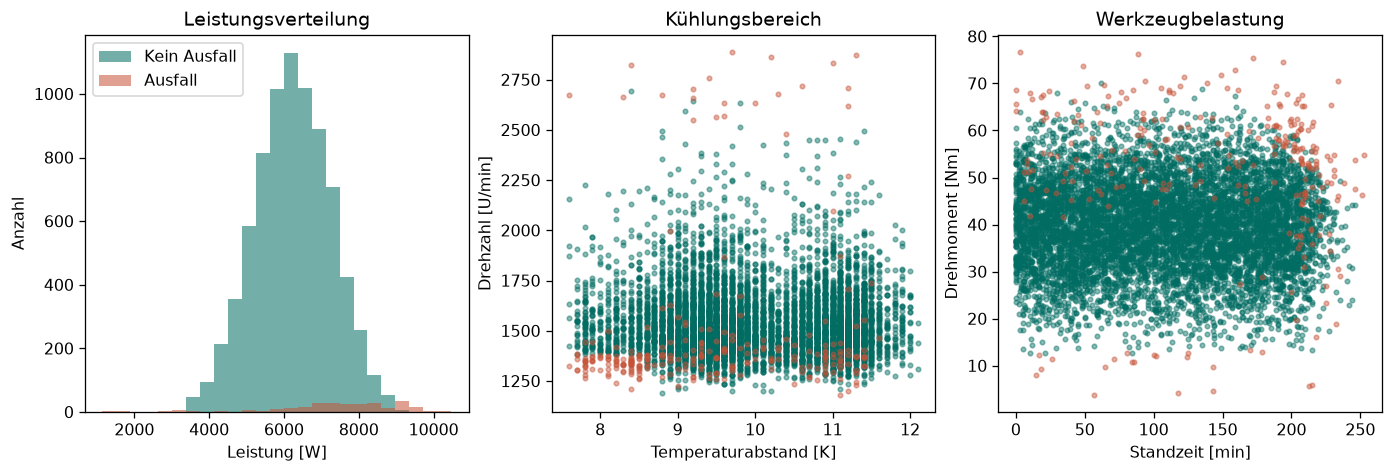

In [7]:
# V4, Zeile 1: Führt den Zeichenblock aus, wenn die Figurklasse verfügbar ist.
if Figure is not None:
    # V4, Zeile 2: Erstellt eine 12 × 4 Zoll große Figur mit automatisch angepassten Abständen.
    fig = Figure(figsize=(12, 4), layout="constrained")
    # V4, Zeile 3: Legt drei nebeneinanderstehende Zeichenflächen an.
    axes = fig.subplots(1, 3)
    # V4, Zeile 4: Bestimmt das gemeinsame Minimum und Maximum der Leistung für beide Klassen.
    bereich = (modell_merkmale["Leistung [W]"].min(), modell_merkmale["Leistung [W]"].max())
    # V4, Zeile 5: Durchläuft normale Vorgänge in Grün und Ausfälle in Orange mit jeweils passender Legendenbezeichnung.
    for klasse, farbe, name in [(0, "#006C62", "Kein Ausfall"), (1, "#C65337", "Ausfall")]:
        # V4, Zeile 6: Markiert alle Zeilen, deren wahres Klassenlabel der gerade betrachteten Klasse entspricht.
        maske = y == klasse
        # V4, Zeile 7: Zeigt deren Leistung in 25 gemeinsamen Intervallen mit 55 % Deckkraft, damit sich die Klassen vergleichen lassen.
        axes[0].hist(modell_merkmale.loc[maske, "Leistung [W]"], bins=25, range=bereich, alpha=.55, label=name, color=farbe)
        # V4, Zeile 8: Beginnt das Streudiagramm des Kühlungsbereichs und verwendet den Temperaturabstand als x-Wert.
        axes[1].scatter(modell_merkmale.loc[maske, "Temperaturabstand [K]"],
                        # V4, Zeile 9: Ergänzt die Drehzahl als y-Wert; kleine Punkte und 45 % Deckkraft machen Überschneidungen sichtbar.
                        modell_merkmale.loc[maske, "Rotational speed [rpm]"], s=8, alpha=.45, color=farbe)
        # V4, Zeile 10: Beginnt das Belastungsdiagramm und verwendet die Werkzeugstandzeit als x-Wert.
        axes[2].scatter(modell_merkmale.loc[maske, "Tool wear [min]"],
                        # V4, Zeile 11: Ergänzt das Drehmoment als y-Wert sowie dieselbe Punktgröße, Deckkraft und Klassenfarbe.
                        modell_merkmale.loc[maske, "Torque [Nm]"], s=8, alpha=.45, color=farbe)
    # V4, Zeile 12: Beschriftet das erste Diagramm mit Leistung, Anzahl der Vorgänge und einem Titel.
    axes[0].set(xlabel="Leistung [W]", ylabel="Anzahl", title="Leistungsverteilung")
    # V4, Zeile 13: Zeigt die im Histogramm vergebenen Klassenbezeichnungen als Legende.
    axes[0].legend()
    # V4, Zeile 14: Beschriftet das Kühlungsdiagramm mit Temperaturabstand und Drehzahl samt Einheiten.
    axes[1].set(xlabel="Temperaturabstand [K]", ylabel="Drehzahl [U/min]", title="Kühlungsbereich")
    # V4, Zeile 15: Beschriftet das Belastungsdiagramm mit Standzeit und Drehmoment samt Einheiten.
    axes[2].set(xlabel="Standzeit [min]", ylabel="Drehmoment [Nm]", title="Werkzeugbelastung")
    # V4, Zeile 16: Zeigt die drei fertigen Teilgrafiken als ein gemeinsames Bild im Notebook.
    diagramm_anzeigen(fig)

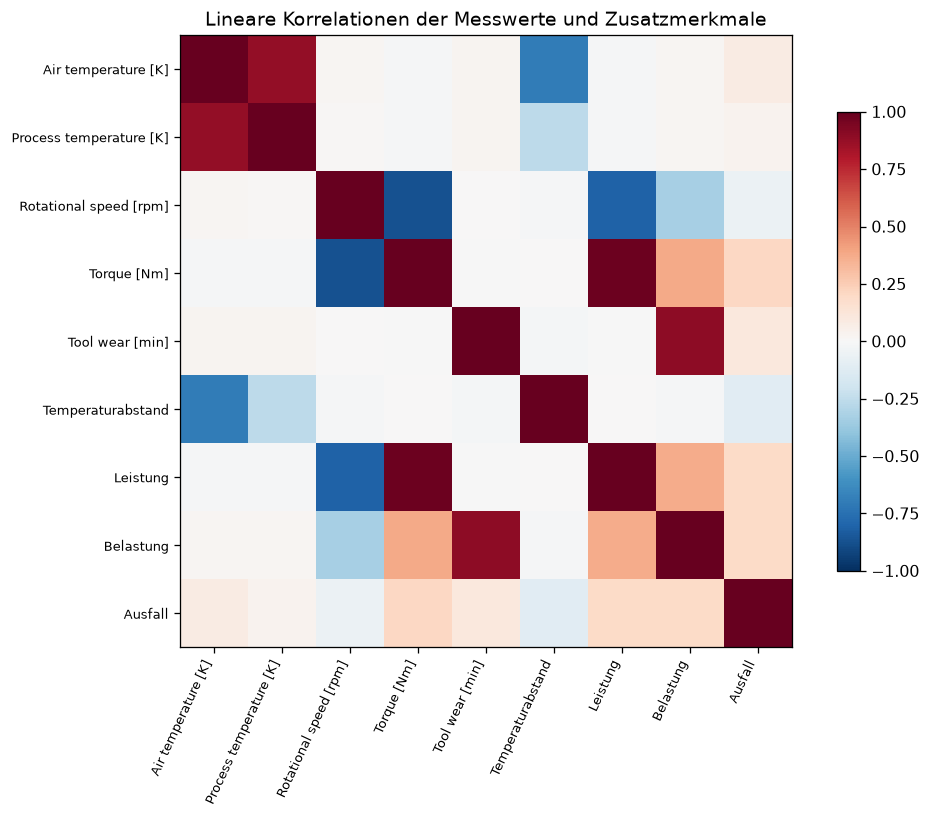

In [8]:
# Physikalische Merkmale für die explorative Darstellung.
# V4, Zeile 2: Berechnet aus X die physikalischen Merkmale. Der nicht benötigte Produkttyp wird mit _ verworfen.
p, dt, rpm, last, _ = merkmale(X)
# V4, Zeile 3: Ergänzt die numerischen Rohwerte um Temperaturabstand, Leistung, Belastung und das bekannte Ausfalllabel.
explorativ = X[FEATURES[1:]].assign(Temperaturabstand=dt, Leistung=p, Belastung=last, Ausfall=y)
# V4, Zeile 4: Zeichnet die Korrelationsmatrix, wenn Matplotlib verfügbar ist.
if Figure is not None:
    # V4, Zeile 5: Erstellt dafür eine 9 × 7 Zoll große Figur.
    fig = Figure(figsize=(9, 7), layout="constrained")
    # V4, Zeile 6: Legt eine einzelne Zeichenfläche an.
    ax = fig.subplots()
    # V4, Zeile 7: Berechnet die paarweisen Pearson-Korrelationen der numerischen Spalten.
    korrelation = explorativ.corr()
    # V4, Zeile 8: Stellt die Korrelationswerte als Farbmatrix auf einer festen Skala von −1 bis +1 dar.
    bild = ax.imshow(korrelation, cmap="RdBu_r", vmin=-1, vmax=1)
    # V4, Zeile 9: Beschriftet die Spalten, dreht ihre Namen um 65 Grad und verwendet rechtsbündige Schriftgröße 8.
    ax.set_xticks(range(len(korrelation)), korrelation.columns, rotation=65, ha="right", fontsize=8)
    # V4, Zeile 10: Beschriftet die Zeilen mit denselben Merkmalsnamen.
    ax.set_yticks(range(len(korrelation)), korrelation.columns, fontsize=8)
    # V4, Zeile 11: Ergänzt eine auf 75 % verkleinerte Farblegende für die Korrelationswerte.
    fig.colorbar(bild, ax=ax, shrink=.75)
    # V4, Zeile 12: Setzt den Titel, der die Grafik als Darstellung linearer Zusammenhänge einordnet.
    ax.set_title("Lineare Korrelationen der Messwerte und Zusatzmerkmale")
    # V4, Zeile 13: Zeigt die fertige Korrelationsgrafik im Notebook.
    diagramm_anzeigen(fig)

## 4 · Modellkandidaten und Regelbildung

Random Forest und logistische Regression werden jeweils mit Rohmerkmalen und mit physikalischen Zusatzmerkmalen geprüft. Bei diesen Paaren bleiben die Modellparameter gleich, sodass sich der Nutzen des Feature Engineerings beobachten lässt.

Zusätzlich werden ein flacher Entscheidungsbaum, ein tieferer Baum, kNN und Gradient Boosting verglichen. Der Kandidat „Baum reine Fehlerblätter“ lernt einen Baum mit mindestens zehn Fällen pro Blatt und alarmiert nur bei einem Ausfallanteil von 100 % im Trainingsblatt. Der eigens entwickelte Regelkern aus V2 bleibt ein separater Vergleich. Er schätzt die Leistungs-, Kühlungs- und Belastungsgrenzen je Trainingsfalte.

In [9]:
# MODELLBEGINN: Logistische Regression mit identischen Parametern für den Merkmalsvergleich.
# V4, Zeile 2: Beginnt das Wörterbuch der Kandidaten; die Schlüssel sind ihre Namen im späteren Ranking.
modelle = {
    # V4, Zeile 3: Definiert eine skalierte Logistik für Rohmerkmale mit C=1 und höchstens 1.000 Optimierungsschritten.
    "Logistik (roh)": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)),
    # V4, Zeile 4: Verwendet dieselbe Logistik-Einstellung mit zusätzlichen Physikmerkmalen für einen direkten Merkmalsvergleich.
    "Logistik (+Physik)": make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=1000)),
# V4, Zeile 5: Schließt das erste Modellwörterbuch.
}

# MODELLBEGINN: Random Forest mit Rohmerkmalen und physikalischen Zusatzmerkmalen.
# V4, Zeile 8: Definiert einen Wald aus 120 Bäumen; ein Blatt enthält mindestens zwei Fälle, Seed 57 macht ihn reproduzierbar und n_jobs=2 begrenzt Parallelität.
rf = RandomForestClassifier(n_estimators=120, min_samples_leaf=2, random_state=57, n_jobs=2)
# V4, Zeile 9: Legt zwei frische Kopien des Waldes für Roh- und Physikmerkmale an.
modelle.update({"Random Forest (roh)": clone(rf), "Random Forest (+Physik)": clone(rf)})

# MODELLBEGINN: Entscheidungsbäume für Vergleich und Interpretation.
# V4, Zeile 12: Beginnt die Ergänzung des Modellwörterbuchs um drei Baumvarianten.
modelle.update({
    # V4, Zeile 13: Definiert einen übersichtlichen Baum mit höchstens drei Ebenen von Splits und mindestens zehn Fällen pro Blatt.
    "Baum Tiefe 3": DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, random_state=57),
    # V4, Zeile 14: Erlaubt dem zweiten Baum bis zu sechs Ebenen bei derselben Mindestblattgröße.
    "Baum Tiefe 6": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10, random_state=57),
    # V4, Zeile 15: Definiert einen Baum ohne feste Tiefenbegrenzung, dessen Blätter mindestens zehn Fälle enthalten; sein Alarmkriterium folgt in der Auswertung.
    "Baum reine Fehlerblätter": DecisionTreeClassifier(min_samples_leaf=10, random_state=57),
# V4, Zeile 16: Schließt die Ergänzung der Baumkandidaten.
})

# MODELLBEGINN: kNN und Boosting als ergänzende Vorlesungsmodelle.
# V4, Zeile 19: Definiert kNN mit 15 Nachbarn und einer nur beim Fit gelernten Standardisierung.
modelle["kNN k=15"] = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))
# V4, Zeile 20: Beginnt die Definition des Histogram-Gradient-Boosting-Modells.
modelle["Gradient Boosting"] = HistGradientBoostingClassifier(
    # V4, Zeile 21: Begrenzt das Boosting auf 120 Iterationen, Baumtiefe 3 und mindestens 20 Fälle pro Blatt; der Seed fixiert seine Zufallsentscheidungen.
    max_iter=120, max_depth=3, min_samples_leaf=20, random_state=57,
# V4, Zeile 22: Schließt den Konstruktor des Boosting-Modells.
)

# Für "(roh)" entfallen nur die drei physikalischen Zusatzspalten.
# V4, Zeile 25: Definiert die Rohmerkmale aus fünf Messwerten und drei 0/1-Spalten für den Produkttyp; * entpackt die Spaltenliste.
rohspalten = [*FEATURES[1:], "Type_L", "Type_M", "Type_H"]
# V4, Zeile 26: Beginnt das Wörterbuch, das jedem Modell seine Merkmaltabelle zuordnet.
modelldaten = {
    # V4, Zeile 27: Wählt für Namen mit (roh) nur die Rohspalten; alle anderen Kandidaten bekommen zusätzlich die Physikmerkmale.
    name: modell_merkmale[rohspalten] if name.endswith("(roh)") else modell_merkmale
    # V4, Zeile 28: Erzeugt diesen Eintrag für jeden Modellnamen.
    for name in modelle
# V4, Zeile 29: Schließt das Wörterbuch der Modellinputs.
}

In [10]:
# V4, Zeile 1: Definiert die Wahl einer Grenze innerhalb einer Lücke zwischen zwei beobachteten Werten.
def schnitt(von, bis, raster):
    # V4, Zeile 2: Testet die vorgegebenen Rundungsraster in ihrer Prioritätsreihenfolge.
    for einheit in raster:
        # V4, Zeile 3: Berechnet den nächsten Rasterwert oberhalb des unteren Lückenrands.
        kandidat = (np.floor(von / einheit) + 1) * einheit
        # V4, Zeile 4: Prüft, ob dieser Rasterwert noch innerhalb der entscheidungsäquivalenten Lücke liegt.
        if von < kandidat <= bis:
            # V4, Zeile 5: Verwendet den ersten passenden Rasterwert als Grenze.
            return kandidat
    # V4, Zeile 6: Verwendet sonst die Lückenmitte und sichert mit nextafter einen Wert strikt oberhalb des unteren Rands.
    return max(von + (bis - von) / 2, np.nextafter(von, bis))

# V4, Zeile 8: Definiert die Suche nach einer Untergrenze, die Trainingsausfälle ohne normalen Trainingsfall erfasst.
def untergrenze(werte, ziel, raster):
    # V4, Zeile 9: Wählt die Merkmalswerte der normalen Vorgänge aus.
    normal = werte[ziel == 0]
    # V4, Zeile 10: Bestimmt den kleinsten normalen Wert; fehlen normale Fälle, wird die Obergrenze unendlich.
    erster_normaler = normal.min() if len(normal) else np.inf
    # V4, Zeile 11: Wählt Ausfälle aus, deren Wert strikt unter dem kleinsten normalen Wert liegt.
    treffer = werte[(ziel == 1) & (werte < erster_normaler)]
    # V4, Zeile 12: Prüft, ob überhaupt ein solcher Ausfall existiert.
    if not len(treffer):
        # V4, Zeile 13: Deaktiviert die Untergrenzenregel, falls sie keinen Ausfall erfassen kann.
        return -np.inf, 0
    # V4, Zeile 14: Wählt eine Grenze zwischen letztem Treffer und erstem Normalfall; ohne Normalfälle wird alles unter unendlich erfasst.
    grenze = schnitt(treffer.max(), erster_normaler, raster) if len(normal) else np.inf
    # V4, Zeile 15: Gibt Grenze und Zahl der reinen Trainingstreffer zurück.
    return grenze, len(treffer)

# V4, Zeile 17: Definiert die gemeinsame Suche nach Temperatur- und Drehzahlgrenze für den Kühlungsalarm.
def kuehlgrenzen(abstand, drehzahl, ziel):
    # V4, Zeile 18: Erstellt die aufsteigend sortierte Liste unterschiedlicher Temperaturabstände im Training.
    kandidaten = np.unique(abstand)
    # V4, Zeile 19: Startet mit einer deaktivierten Regel und null erfassten Ausfällen.
    bestes_paar, beste_treffer = (-np.inf, -np.inf), 0
    # V4, Zeile 20: Testet jeden beobachteten Temperaturabstand und merkt sich seine Position.
    for i, wert in enumerate(kandidaten):
        # V4, Zeile 21: Wählt die Vorgänge mit einem Temperaturabstand bis zum aktuellen Kandidaten aus.
        innen = abstand <= wert
        # V4, Zeile 22: Sucht innerhalb dieser Auswahl eine Drehzahlgrenze mit reinen Ausfalltreffern.
        rpm, treffer = untergrenze(drehzahl[innen], ziel[innen], (10, 1))
        # V4, Zeile 23: Übernimmt die Kombination nur, wenn sie mehr Trainingsausfälle erfasst als die bisher beste.
        if treffer > beste_treffer:
            # V4, Zeile 24: Bestimmt den nächsten beobachteten Temperaturwert oder unendlich am Ende der Liste.
            naechster = kandidaten[i + 1] if i + 1 < len(kandidaten) else np.inf
            # V4, Zeile 25: Setzt die Temperaturgrenze in die nächste Lücke und speichert sie zusammen mit Drehzahlgrenze und Trefferzahl.
            bestes_paar, beste_treffer = (schnitt(wert, naechster, (0.1,)), rpm), treffer
    # V4, Zeile 26: Gibt die beste Kombination beider Grenzen zurück.
    return bestes_paar

# V4, Zeile 28: Definiert die Suche nach einem Grundwert und typabhängigen Abständen der Belastungsgrenzen.
def belastungsgrenzen(last, typ, ziel):
    # V4, Zeile 29: Testet Typabstände von 0 bis 3.000 in 100er-Schritten; bei Gleichstand werden zuerst einfachere 1.000er-/500er-Abstände betrachtet.
    abstaende = sorted(range(0, 3001, 100), key=lambda a: (a % 1000 != 0, a % 500 != 0, a))
    # V4, Zeile 30: Initialisiert den Bestwert unterhalb jeder möglichen Trefferzahl, damit der erste Kandidat übernommen wird.
    beste_treffer = -1
    # V4, Zeile 31: Testet jeden möglichen Abstand zwischen den Typstufen.
    for abstand in abstaende:
        # V4, Zeile 32: Verschiebt die Belastung um den Typabstand und nutzt die Untergrenzensuche für die entsprechend negierte Belastungsregel.
        grenze, treffer = untergrenze(abstand * typ - last, ziel, (1000, 100, 10))
        # V4, Zeile 33: Prüft, ob der Kandidat mehr reine Trainingsausfälle erfasst.
        if treffer > beste_treffer:
            # V4, Zeile 34: Rechnet die gefundene Grenze in drei Obergrenzen für L, M und H zurück und merkt sich die Trefferzahl.
            grenzen, beste_treffer = -grenze + abstand * np.arange(len(TYP)), treffer
    # V4, Zeile 35: Gibt die drei gemeinsam gelernten Belastungsgrenzen zurück.
    return grenzen

In [11]:
# MODELLBEGINN: Physikalische Regeln für Leistung, Kühlung und Werkzeugbelastung.
# V4, Zeile 2: Definiert das Lernen der physikalischen Regeln aus Messwerten und bekannten Zielklassen.
def regeln_lernen(frame, ziel):
    # V4, Zeile 3: Berechnet die fünf Merkmalsarrays für das Training.
    leistung, abstand, drehzahl, last, typ = merkmale(frame)
    # V4, Zeile 4: Beginnt ohne aktive Kühlungsalarme; ein boolescher Wert repräsentiert jeweils einen Vorgang.
    kuehlalarm = np.zeros(len(ziel), dtype=bool)
    # V4, Zeile 5: Beginnt auch ohne aktive Belastungsalarme.
    lastalarm = np.zeros(len(ziel), dtype=bool)
    # V4, Zeile 6: Legt die bevorzugten einfachen Raster für die Leistungsgrenzen fest.
    raster = (1000, 100, 50, 10)
    # Drei Durchläufe stimmen jede Grenze auf den Rest ohne die anderen Alarme ab.
    # V4, Zeile 8: Wiederholt die Abstimmung der Regeln dreimal; die Zählvariable selbst wird nicht benötigt.
    for _ in range(3):
        # V4, Zeile 9: Wählt die Fälle aus, die bisher weder Kühlungs- noch Belastungsalarm auslösen.
        rest = ~(kuehlalarm | lastalarm)
        # V4, Zeile 10: Lernt auf diesen Restfällen die untere Leistungsgrenze; die zurückgegebene Trefferzahl wird hier verworfen.
        tief, _ = untergrenze(leistung[rest], ziel[rest], raster)
        # V4, Zeile 11: Negiert die Leistung, damit dieselbe Suchfunktion auch eine obere Leistungsgrenze lernen kann.
        negativ_hoch, _ = untergrenze(-leistung[rest], ziel[rest], raster)
        # V4, Zeile 12: Kehrt das Vorzeichen der gefundenen Grenze für die tatsächliche obere Leistungsgrenze wieder um.
        hoch = -negativ_hoch
        # V4, Zeile 13: Markiert Vorgänge unterhalb oder oberhalb des gelernten Leistungsfensters.
        leistung_alarm = (leistung < tief) | (leistung > hoch)
        # V4, Zeile 14: Wählt für die Kühlungsregel die Fälle ohne Leistungs- oder Belastungsalarm aus.
        rest = ~(leistung_alarm | lastalarm)
        # V4, Zeile 15: Lernt Temperatur- und Drehzahlgrenze aus diesen verbleibenden Fällen.
        delta, rpm = kuehlgrenzen(abstand[rest], drehzahl[rest], ziel[rest])
        # V4, Zeile 16: Löst Kühlungsalarm nur bei gleichzeitig kleinem Temperaturabstand und niedriger Drehzahl aus.
        kuehlalarm = (abstand < delta) & (drehzahl < rpm)
        # V4, Zeile 17: Wählt für die Belastungsregel die Fälle ohne Leistungs- oder Kühlungsalarm aus.
        rest = ~(leistung_alarm | kuehlalarm)
        # V4, Zeile 18: Lernt die typabhängigen Belastungsobergrenzen auf diesem Rest.
        lastgrenzen = belastungsgrenzen(last[rest], typ[rest], ziel[rest])
        # V4, Zeile 19: Vergleicht jeden Vorgang mit der Grenze seiner Produktstufe.
        lastalarm = last > lastgrenzen[typ]
    # V4, Zeile 20: Gibt die fünf Bestandteile des trainierten Regelmodells zurück.
    return tief, hoch, delta, rpm, lastgrenzen

# V4, Zeile 22: Definiert die Anwendung bereits gelernter Grenzen auf weitere Vorgänge.
def regelalarm(frame, grenzen):
    # V4, Zeile 23: Berechnet dazu dieselben physikalischen Merkmale wie im Training.
    leistung, abstand, drehzahl, last, typ = merkmale(frame)
    # V4, Zeile 24: Entpackt die fünf Grenzbestandteile in benannte Variablen.
    tief, hoch, delta, rpm, lastgrenzen = grenzen
    # V4, Zeile 25: Beginnt die ODER-Verknüpfung der Alarme bei zu kleiner oder zu großer Leistung.
    return ((leistung < tief) | (leistung > hoch)
            # V4, Zeile 26: Ergänzt Kühlung und Belastung per ODER; innerhalb der Kühlungsregel müssen beide Bedingungen gleichzeitig gelten.
            | ((abstand < delta) & (drehzahl < rpm)) | (last > lastgrenzen[typ]))

## 5 · Verschleißmodell und Alarmschwelle

Die logistische Regression (L2-Regularisierung, $C=1$) wird auf den Trainingsvorgängen ohne Regelalarm angepasst. Ihre Merkmale sind die Produktstufe und die Standzeit oberhalb des ersten Zehn-Minuten-Bands mit mindestens 30 Vorgängen und mindestens 2 % Ausfällen. Beide Merkmale werden anhand der Trainingsdaten standardisiert.

Bei geschätztem Ausfallrisiko $p$ betragen die erwarteten Kosten der Freigabe $6p$ und die des Alarms $1-p$. Daher wird die Schwelle der zweiten Stufe auf **$1/7$** gesetzt. Das Hybridmodell alarmiert, sobald eine physikalische Regel oder die Verschleißstufe einen Alarm auslöst.

In [12]:
# V4, Zeile 1: Definiert die beiden Eingangsmerkmale für die zusätzliche Verschleißlogistik.
def verschleissmerkmale(frame, beginn):
    # V4, Zeile 2: Liest die Werkzeugstandzeit als numerisches Array aus.
    standzeit = frame["Tool wear [min]"].to_numpy(float)
    # V4, Zeile 3: Kodiert den Produkttyp als geordnete Stufe.
    typ = frame["Type"].map(TYP).to_numpy()
    # V4, Zeile 4: Verbindet den positiven Standzeitüberschuss über dem Beginn und den Produkttyp zu zwei Spalten.
    return np.column_stack((np.maximum(standzeit - beginn, 0), typ))

# MODELLBEGINN: Hybrid aus Regelalarm und logistischer Regression.
# V4, Zeile 7: Definiert das Training des gesamten Hybrids aus Regelkern und Verschleißstufe.
def hybrid_trainieren(frame, ziel):
    # V4, Zeile 8: Lernt zunächst die physikalischen Regelgrenzen aus den Trainingsfällen.
    grenzen = regeln_lernen(frame, ziel)
    # V4, Zeile 9: Wählt die Trainingsvorgänge ohne Alarm aus der ersten Stufe aus.
    rest = ~regelalarm(frame, grenzen)
    # V4, Zeile 10: Ordnet die Standzeiten dieser Vorgänge Zehn-Minuten-Bändern zu; 207 wird zum Beispiel zu 200.
    band = (frame.loc[rest, "Tool wear [min]"] // 10) * 10
    # V4, Zeile 11: Berechnet pro Band die Zahl der Fälle und deren Ausfallquote; der Mittelwert binärer Labels ist die Quote.
    statistik = pd.Series(ziel[rest], index=band.index).groupby(band).agg(["size", "mean"])
    # Erstes Zehn-Minuten-Band mit mindestens 30 Fällen und 2 % Ausfällen.
    # V4, Zeile 13: Wählt Bänder mit mindestens 30 Vorgängen und mindestens zwei Prozent Ausfällen.
    passend = statistik[(statistik["size"] >= 30) & (statistik["mean"] >= 0.02)]
    # V4, Zeile 14: Prüft, ob ein geeignetes Band oder eine der beiden Zielklassen in den Restfällen fehlt.
    if passend.empty or np.unique(ziel[rest]).size < 2:
        # V4, Zeile 15: Gibt dann nur den Regelkern zurück; None kennzeichnet die fehlende Verschleißstufe.
        return grenzen, None, None
    # V4, Zeile 16: Verwendet den Beginn des frühesten passenden Bands als Knickpunkt des Standzeitmerkmals.
    beginn = float(passend.index.min())
    # V4, Zeile 17: Verbindet Standardisierung und regularisierte logistische Regression mit C=1 in einer Pipeline.
    logistik = make_pipeline(StandardScaler(), LogisticRegression(C=1.0))
    # V4, Zeile 18: Lernt Skalierung und Regressionskoeffizienten nur anhand der Restfälle des Trainings.
    logistik.fit(verschleissmerkmale(frame.loc[rest], beginn), ziel[rest])
    # V4, Zeile 19: Gibt Regelgrenzen, Verschleißbeginn und trainierte Pipeline als Modellpaket zurück.
    return grenzen, beginn, logistik

# V4, Zeile 21: Definiert die gemeinsame Vorhersage des Regelkerns und des Hybrids.
def vorhersagen(frame, modell):
    # V4, Zeile 22: Entpackt die drei Bestandteile des Modellpakets.
    grenzen, beginn, logistik = modell
    # V4, Zeile 23: Berechnet zuerst den booleschen Alarm des Regelkerns.
    kern = regelalarm(frame, grenzen)
    # V4, Zeile 24: Prüft, ob beim Training keine Verschleißstufe gelernt werden konnte.
    if logistik is None:
        # V4, Zeile 25: Liefert in diesem Fall zweimal dieselbe 0/1-Regelvorhersage für den Vergleich.
        return kern.astype(int), kern.astype(int)
    # V4, Zeile 26: Berechnet den Score für Ausfallklasse 1; [:, 1] nimmt die zweite Wahrscheinlichkeitsspalte.
    score = logistik.predict_proba(verschleissmerkmale(frame, beginn))[:, 1]
    # V4, Zeile 27: Gibt separat den Regelalarm und dessen ODER-Verknüpfung mit dem Verschleißalarm ab 1/7 zurück.
    return kern.astype(int), (kern | (score >= SCHWELLE)).astype(int)

## 6 · Kostenvergleich und Fehlertypen

Bewertet werden FP + 6 × FN sowie die Gütemaße aus der Vorlesung. Jede Tabellenzeile der Einzelergebnisse umfasst 8.000 gehaltene Vorhersagen pro Seed. „Innere Modellauswahl“ wählt je äußerer Trainingsfalte einen der Standardkandidaten nach inneren Kosten. Der Vergleich aller äußeren Mittelwerte dient der weiteren Modellentwicklung auf dieser Kohorte.

Physikalisch plausible Alarmgruppen sind anhand der binären Zielspalte untersuchbar. Eine Zuordnung zu tatsächlichen Fehlerarten verlangt zusätzliche Labels. Ein reines Trainingsblatt beweist weder einen deterministischen Ausfallmechanismus noch eine theoretische Kostenuntergrenze.

In [13]:
# V4, Zeile 1: Definiert die gemeinsame Berechnung von Fehlerzahlen, Kosten und Gütemaßen.
def kennzahlen(wahr, prognose):
    # V4, Zeile 2: Liest die Konfusionsmatrix in der Reihenfolge TN, FP, FN, TP aus; labels fixiert die Klassenreihenfolge.
    tn, fp, fn, tp = confusion_matrix(wahr, prognose, labels=[0, 1]).ravel()
    # V4, Zeile 3: Beginnt das Wörterbuch der Kennzahlen eines Vorhersagelaufs.
    return {
        # V4, Zeile 4: Speichert die vier Fallzahlen und berechnet die aufgabenbezogenen Kosten FP + 6×FN.
        "TN": tn, "FP": fp, "FN": fn, "TP": tp, "Kosten": fp + KOSTEN_FN * fn,
        # V4, Zeile 5: Berechnet den Anteil richtiger Vorhersagen und den Anteil aller Fehlvorhersagen.
        "Accuracy": (tp + tn) / len(wahr), "Error Rate": (fp + fn) / len(wahr),
        # V4, Zeile 6: Berechnet den Anteil echter Ausfälle unter den Alarmen; bei null Alarmen wird der Wert auf 0 gesetzt.
        "Precision": tp / (tp + fp) if tp + fp else 0.0,
        # V4, Zeile 7: Berechnet Erkennungsrate unter den Ausfällen und Freigaberate unter normalen Vorgängen.
        "Recall": tp / (tp + fn), "Specificity": tn / (tn + fp),
        # V4, Zeile 8: Berechnet Fehlalarmrate unter normalen Vorgängen und Übersehensrate unter den Ausfällen.
        "FPR": fp / (tn + fp), "FNR": fn / (tp + fn),
    # V4, Zeile 9: Schließt das Kennzahlenwörterbuch und gibt es zurück.
    }

# V4, Zeile 11: Definiert die Wahl der Alarmschwelle anhand von Zielwerten und inneren Prüfscores.
def schwelle_waehlen(ziel, score):
    # Gleiche Scores zusammenhalten und alle möglichen Betriebspunkte zählen.
    # V4, Zeile 13: Sortiert die Positionen absteigend nach Score; bei Gleichstand bleibt die ursprüngliche Reihenfolge stabil.
    sortierung = np.argsort(-score, kind="stable")
    # V4, Zeile 14: Ordnet die Scores nach dieser Sortierung an.
    sortierte_scores = score[sortierung]
    # V4, Zeile 15: Findet das Ende jeder Gruppe gleicher Scores und ergänzt die letzte Position.
    enden = np.r_[np.flatnonzero(np.diff(sortierte_scores) != 0), len(score) - 1]
    # V4, Zeile 16: Bewertet einen zusätzlichen Alarm mit −6 Kosten bei echtem Ausfall oder +1 bei normalem Vorgang.
    aenderung = np.where(ziel[sortierung] == 1, -KOSTEN_FN, 1)
    # V4, Zeile 17: Startet mit den Kosten für keinen Alarm und summiert dann die Änderungen an allen zulässigen Scoregrenzen.
    kosten = KOSTEN_FN * ziel.sum() + np.r_[0, np.cumsum(aenderung)[enden]]
    # V4, Zeile 18: Ordnet jedem Betriebspunkt eine Schwelle zu; unendlich entspricht keinem Alarm.
    grenzen = np.r_[np.inf, sortierte_scores[enden]]
    # V4, Zeile 19: Findet das erste Kostenminimum; bei Gleichstand ist das der Betriebspunkt mit weniger Alarmen.
    beste_position = int(np.argmin(kosten))
    # V4, Zeile 20: Gibt die gewählte Schwelle und ihre inneren Validierungskosten zurück.
    return float(grenzen[beste_position]), int(kosten[beste_position])

# V4, Zeile 22: Legt Listen für die Gesamtkennzahlen und die Entscheidungen pro äußerer Falte an.
ergebnisse, faltenergebnisse = [], []
# V4, Zeile 23: Legt eine Liste für die späteren Diagnosetabellen der zurückgehaltenen Fälle an.
pruefdiagnosen = []
# V4, Zeile 24: Begrenzt die Parallelität der numerischen Bibliotheken während des Vergleichs auf zwei Threads.
with threadpool_limits(limits=2):
    # V4, Zeile 25: Durchläuft die fünf vorab festgelegten Zufallsaufteilungen.
    for seed in SEEDS:
        # V4, Zeile 26: Stellt die beiden Referenzen, den Hybrid, alle Standardmodelle und die innere Auswahlstrategie zusammen.
        namen = ["Nie Alarm", "Physikalische Regeln", "Hybrid", *modelle, "Innere Modellauswahl"]
        # V4, Zeile 27: Reserviert je Modell ein Vorhersagearray mit einer Position pro beschriftetem Vorgang.
        prognosen_cv = {name: np.zeros_like(y) for name in namen}
        # V4, Zeile 28: Durchläuft die fünf äußeren Trainings-/Prüffalten und nummeriert sie ab 1.
        for nummer, (train, pruefung) in enumerate(falten(seed), 1):
            # V4, Zeile 29: Trainiert einen neuen Hybrid ausschließlich auf den aktuellen äußeren Trainingszeilen.
            hybrid = hybrid_trainieren(X.iloc[train], y[train])
            # V4, Zeile 30: Sagt Regelkern und Hybrid für die zurückgehaltene äußere Prüffalte vorher.
            kern_pred, hybrid_pred = vorhersagen(X.iloc[pruefung], hybrid)
            # V4, Zeile 31: Schreibt die Regelvorhersagen an die ursprünglichen Positionen der Prüffälle.
            prognosen_cv["Physikalische Regeln"][pruefung] = kern_pred
            # V4, Zeile 32: Schreibt entsprechend die Hybridvorhersagen zurück.
            prognosen_cv["Hybrid"][pruefung] = hybrid_pred

            # Schwellenwahl ausschließlich aus inneren Out-of-Fold-Scores.
            # V4, Zeile 35: Definiert drei innere Falten ausschließlich innerhalb der äußeren Trainingsgruppe.
            innen = StratifiedKFold(n_splits=3, shuffle=True, random_state=seed + 100 * nummer)
            # V4, Zeile 36: Speichert deren relativen Trainings-/Validierungspositionen, damit alle Kandidaten dieselben inneren Splits verwenden.
            splits = list(innen.split(modell_merkmale.iloc[train], y[train]))
            # V4, Zeile 37: Beginnt je äußerer Falte leere Wörterbücher für innere Kosten und gewählte Schwellen.
            innere_kosten, schwellen = {}, {}
            # V4, Zeile 38: Durchläuft alle vorab definierten scikit-learn-Kandidaten.
            for name, kandidat in modelle.items():
                # V4, Zeile 39: Wählt die zum Modell gehörenden Roh- oder Physikmerkmale aus.
                eingabe = modelldaten[name]
                # V4, Zeile 40: Reserviert einen Score pro Vorgang der äußeren Trainingsgruppe für die inneren Prüfvorhersagen.
                score_innen = np.empty(len(train))
                # V4, Zeile 41: Durchläuft die drei inneren Trainings-/Validierungsaufteilungen.
                for fit, valid in splits:
                    # V4, Zeile 42: Trainiert eine frische Modellkopie auf dem inneren Training; train[fit] übersetzt relative in ursprüngliche Zeilenpositionen.
                    teilmodell = clone(kandidat).fit(eingabe.iloc[train[fit]], y[train[fit]])
                    # V4, Zeile 43: Speichert Ausfallscores der inneren Validierung an deren relativen Positionen.
                    score_innen[valid] = teilmodell.predict_proba(eingabe.iloc[train[valid]])[:, 1]
                # V4, Zeile 44: Behandelt den bewusst auf reine Fehlerblätter beschränkten Baum separat.
                if name == "Baum reine Fehlerblätter":
                    # V4, Zeile 45: Setzt seine Schwelle fest auf einen Ausfallanteil von 100 Prozent im Trainingsblatt.
                    grenze = 1.0
                    # V4, Zeile 46: Berechnet die inneren Kosten bei diesem festen Alarmkriterium.
                    kosten_innen = kennzahlen(y[train], score_innen >= grenze)["Kosten"]
                # V4, Zeile 47: Leitet den Zweig für alle übrigen Standardmodelle ein.
                else:
                    # V4, Zeile 48: Bestimmt deren kostengünstigste Schwelle aus den vollständigen inneren Out-of-Fold-Scores.
                    grenze, kosten_innen = schwelle_waehlen(y[train], score_innen)
                # V4, Zeile 49: Speichert innere Kosten und Schwelle für den jeweiligen Kandidaten.
                innere_kosten[name], schwellen[name] = kosten_innen, grenze
                # V4, Zeile 50: Trainiert den Kandidaten anschließend erneut auf der ganzen äußeren Trainingsgruppe.
                gelernt = clone(kandidat).fit(eingabe.iloc[train], y[train])
                # V4, Zeile 51: Berechnet seine Scores für die äußere Prüffalte, die bisher unberührt blieb.
                score_aussen = gelernt.predict_proba(eingabe.iloc[pruefung])[:, 1]
                # V4, Zeile 52: Wendet die innen gewählte Schwelle auf diese Scores an und speichert die 0/1-Vorhersagen.
                prognosen_cv[name][pruefung] = score_aussen >= grenze
                # V4, Zeile 53: Wählt den kleinen Baum aus der ersten äußeren Falte des ersten Seeds als Interpretationsbeispiel.
                if seed == SEEDS[0] and nummer == 1 and name == "Baum Tiefe 3":
                    # V4, Zeile 54: Merkt sich dafür das tatsächlich trainierte Modell.
                    kleiner_baum = gelernt
                    # V4, Zeile 55: Merkt sich seine innerlich gewählte Alarmschwelle für die Beschriftung.
                    baum_schwelle = grenze
                # V4, Zeile 56: Beschränkt die folgenden Diagnosebeispiele ebenfalls auf diese erste Trainingsfalte.
                if seed == SEEDS[0] and nummer == 1:
                    # V4, Zeile 57: Wählt den Random Forest mit zusätzlichen Physikmerkmalen für die Schwellenkurve aus.
                    if name == "Random Forest (+Physik)":
                        # V4, Zeile 58: Kopiert ausschließlich dessen innere Zielwerte und Prüfscores für die spätere Darstellung.
                        tuning_ziel, tuning_score = y[train].copy(), score_innen.copy()
                    # V4, Zeile 59: Wählt den Baum mit reinen Trainingsfehlerblättern für die Ausgabe seiner Pfade aus.
                    if name == "Baum reine Fehlerblätter":
                        # V4, Zeile 60: Merkt sich den auf der äußeren Trainingsgruppe gelernten Baum.
                        regelbaum = gelernt

            # V4, Zeile 62: Wählt den Kandidaten mit den kleinsten inneren Kosten dieser äußeren Falte.
            gewinner = min(innere_kosten, key=innere_kosten.get)
            # V4, Zeile 63: Übernimmt dessen äußere Vorhersage als Ergebnis der vollständig innen getroffenen Modellauswahl.
            prognosen_cv["Innere Modellauswahl"][pruefung] = prognosen_cv[gewinner][pruefung]
            # V4, Zeile 64: Protokolliert Seed, Falte, ausgewähltes Modell und sämtliche Schwellen.
            faltenergebnisse.append({"Seed": seed, "Falte": nummer, "Auswahl": gewinner, "Schwellen": schwellen})
        # Diagnose aller gehaltenen Ausfälle und Freigaben, ohne Rückwirkung auf das Training.
        # V4, Zeile 66: Beginnt die Diagnosetabelle des aktuellen Seeds nach Abschluss aller fünf Prüffalten.
        pruefdiagnosen.append(pd.DataFrame({
            # V4, Zeile 67: Speichert den Seed, die tatsächlichen Labels und die einmalig gehaltenen Regelvorhersagen.
            "Seed": seed, "Ausfall": y, "Regelalarm": prognosen_cv["Physikalische Regeln"],
            # V4, Zeile 68: Ergänzt die Hybridvorhersagen und Standzeiten in derselben ursprünglichen Zeilenreihenfolge.
            "Hybridalarm": prognosen_cv["Hybrid"], "Standzeit": X["Tool wear [min]"].to_numpy(),
        # V4, Zeile 69: Schließt die Tabelle und hängt sie an die Diagnoseliste an.
        }))
        # V4, Zeile 70: Durchläuft die vollständigen 8.000 Prüfvorhersagen jedes Modells.
        for name, prognose in prognosen_cv.items():
            # V4, Zeile 71: Berechnet pro Modell und Seed die Kennzahlen; ** entpackt das Kennzahlenwörterbuch in die Ergebniszeile.
            ergebnisse.append({"Seed": seed, "Modell": name, **kennzahlen(y, prognose)})
        # V4, Zeile 72: Meldet den Abschluss einer vollständigen fünffachen Kreuzvalidierung.
        print(f"Seed {seed} abgeschlossen.")

# V4, Zeile 74: Wandelt die Liste aller Ergebniszeilen in eine Tabelle um.
cv = pd.DataFrame(ergebnisse)
# V4, Zeile 75: Legt die für den Vergleich angezeigten Kosten, Fehlerzahlen und Gütemaße fest.
metriken = ["Kosten", "FP", "FN", "Accuracy", "Error Rate", "Precision", "Recall", "Specificity", "FPR", "FNR"]
# V4, Zeile 76: Mittelt jede Kennzahl über die Seeds und sortiert die Modelle nach aufsteigenden Kosten.
vergleich = cv.groupby("Modell")[metriken].mean().sort_values("Kosten", kind="stable")
# V4, Zeile 77: Legt fest, welche Gütemaße als Prozentwerte angezeigt werden.
prozent = ["Accuracy", "Error Rate", "Precision", "Recall", "Specificity", "FPR", "FNR"]
# V4, Zeile 78: Kopiert die Mittelwerttabelle, damit die ursprünglichen Anteile zwischen 0 und 1 erhalten bleiben.
anzeige = vergleich.copy()
# V4, Zeile 79: Multipliziert nur die Anzeigespalten mit 100.
anzeige[prozent] *= 100
# V4, Zeile 80: Kennzeichnet die Prozentspalten und zeigt das Kostenranking mit zwei Nachkommastellen.
display(anzeige.rename(columns={name: name + " [%]" for name in prozent}).round(2))
# V4, Zeile 81: Zeigt die Kosten je Modell und Seed in der ursprünglichen Reihenfolge der Seeds.
display(cv.pivot(index="Seed", columns="Modell", values="Kosten").loc[list(SEEDS)])
# V4, Zeile 82: Wählt den Hybridlauf des ersten Seeds für die Konfusionsmatrix aus.
erster_lauf = cv[(cv["Seed"] == SEEDS[0]) & (cv["Modell"] == "Hybrid")].iloc[0]

Seed 2006 abgeschlossen.
Seed 2026 abgeschlossen.
Seed 2007 abgeschlossen.
Seed 888 abgeschlossen.
Seed 1024 abgeschlossen.


,Kosten,FP,FN,Accuracy [%],Error Rate [%],Precision [%],Recall [%],Specificity [%],FPR [%],FNR [%]
Modell,,,,,,,,,,
Hybrid,237.6,25.2,35.4,99.24,0.76,90.34,86.94,99.67,0.33,13.06
Physikalische Regeln,252.0,0.0,42.0,99.48,0.52,100.00,84.50,100.00,0.00,15.50
Innere Modellauswahl,301.8,42.6,43.2,98.93,1.07,84.32,84.06,99.45,0.55,15.94
Random Forest (+Physik),303.4,44.2,43.2,98.91,1.09,83.84,84.06,99.43,0.57,15.94
Baum Tiefe 6,321.6,24.0,49.6,99.08,0.92,90.28,81.70,99.69,0.31,18.30
Gradient Boosting,333.0,77.4,42.6,98.50,1.50,75.03,84.28,99.00,1.00,15.72
Baum reine Fehlerblätter,376.0,0.4,62.6,99.21,0.79,99.81,76.90,99.99,0.01,23.10
Random Forest (roh),452.6,170.6,47.0,97.28,2.72,57.00,82.66,97.79,2.21,17.34
kNN k=15,695.4,277.8,69.6,95.66,4.34,42.14,74.32,96.41,3.59,25.68


Modell,Baum Tiefe 3,Baum Tiefe 6,Baum reine Fehlerblätter,Gradient Boosting,Hybrid,Innere Modellauswahl,Logistik (+Physik),Logistik (roh),Nie Alarm,Physikalische Regeln,Random Forest (+Physik),Random Forest (roh),kNN k=15
Seed,,,,,,,,,,,,,
2006,763,309,372,348,240,303,964,958,1626,252,311,438,695
2026,762,329,378,328,237,306,945,950,1626,252,306,476,667
2007,765,304,366,325,242,283,967,949,1626,252,283,485,709
888,775,315,378,318,235,288,935,941,1626,252,288,412,672
1024,777,351,386,346,234,329,937,927,1626,252,329,452,734


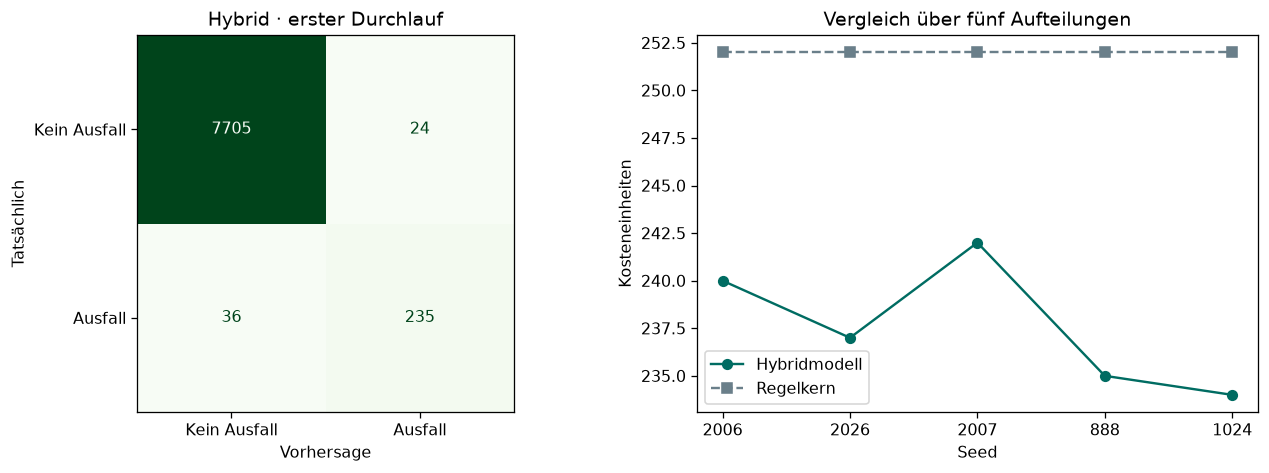

In [14]:
# Werte aus der berechneten Kreuzvalidierung übernehmen.
# V4, Zeile 2: Ordnet die Kosten nach Seed und Modell an und stellt die Reihenfolge der fünf definierten Seeds wieder her.
kosten = cv.pivot(index="Seed", columns="Modell", values="Kosten").loc[list(SEEDS)]
# V4, Zeile 3: Beginnt den Aufbau der 2 × 2-Konfusionsmatrix aus dem ersten Hybrid-Durchlauf.
matrix = np.array([
    # V4, Zeile 4: Die erste Matrixzeile enthält korrekt freigegebene Vorgänge und Fehlalarme bei tatsächlich normalen Vorgängen.
    [erster_lauf["TN"], erster_lauf["FP"]],
    # V4, Zeile 5: Die zweite Matrixzeile enthält übersehene und erkannte tatsächliche Ausfälle.
    [erster_lauf["FN"], erster_lauf["TP"]],
# V4, Zeile 6: Schließt die Matrixdefinition und wandelt die beiden Zeilen in ein NumPy-Array um.
])
# V4, Zeile 7: Prüft, ob neue Grafiken wegen fehlendem Matplotlib ausfallen.
if Figure is None:
    # V4, Zeile 8: Gibt für diesen Fall einen Installationshinweis aus.
    print("Für neu gerenderte Diagramme: %pip install matplotlib. Die Tabellen bleiben verfügbar.")
# V4, Zeile 9: Beginnt andernfalls die grafische Auswertung.
else:
    # V4, Zeile 10: Lädt die Standarddarstellung einer Konfusionsmatrix aus scikit-learn.
    from sklearn.metrics import ConfusionMatrixDisplay

    # Links die Fehlertypen, rechts die Kostenstabilität auf denselben Seeds.
    # V4, Zeile 13: Erstellt eine 11 × 4 Zoll große Figur für zwei nebeneinanderstehende Grafiken.
    fig = Figure(figsize=(11, 4), layout="constrained")
    # V4, Zeile 14: Legt die linke Zeichenfläche für die Matrix und die rechte für die Kosten an.
    axes = fig.subplots(1, 2)
    # V4, Zeile 15: Startet die grafische Matrixdarstellung und benennt die Klassen ausdrücklich als kein Ausfall und Ausfall.
    ConfusionMatrixDisplay(matrix, display_labels=["Kein Ausfall", "Ausfall"]).plot(
        # V4, Zeile 16: Zeichnet die Matrix links, ohne Farbleiste, mit grüner Farbskala und ganzzahligen Zellwerten.
        ax=axes[0], colorbar=False, cmap="Greens", values_format="d"
    # V4, Zeile 17: Schließt den Aufruf zum Zeichnen der Konfusionsmatrix ab.
    )
    # V4, Zeile 18: Beschriftet die Spalten als Vorhersagen und die Zeilen als tatsächliche Klassen des ersten Hybrid-Durchlaufs.
    axes[0].set(xlabel="Vorhersage", ylabel="Tatsächlich", title="Hybrid · erster Durchlauf")
    # V4, Zeile 19: Wandelt die Seeds in Texte um, damit sie als gleichmäßig verteilte Kategorien auf der x-Achse erscheinen.
    labels = [str(seed) for seed in SEEDS]
    # V4, Zeile 20: Zeichnet die Hybridkosten je Seed als grüne Linie mit Kreispunkten.
    axes[1].plot(labels, kosten["Hybrid"], "o-", color="#006C62", label="Hybridmodell")
    # V4, Zeile 21: Zeichnet die Regelkernkosten als graue gestrichelte Linie mit quadratischen Punkten.
    axes[1].plot(labels, kosten["Physikalische Regeln"], "s--", color="#6A7F8A", label="Regelkern")
    # V4, Zeile 22: Beschriftet den Kostenvergleich mit Seed und Kosteneinheiten.
    axes[1].set(xlabel="Seed", ylabel="Kosteneinheiten", title="Vergleich über fünf Aufteilungen")
    # V4, Zeile 23: Blendet die Legende ein, die beide Kostenlinien benennt.
    axes[1].legend()
    # V4, Zeile 24: Zeigt Konfusionsmatrix und Kostenverlauf als gemeinsames Bild.
    diagramm_anzeigen(fig)

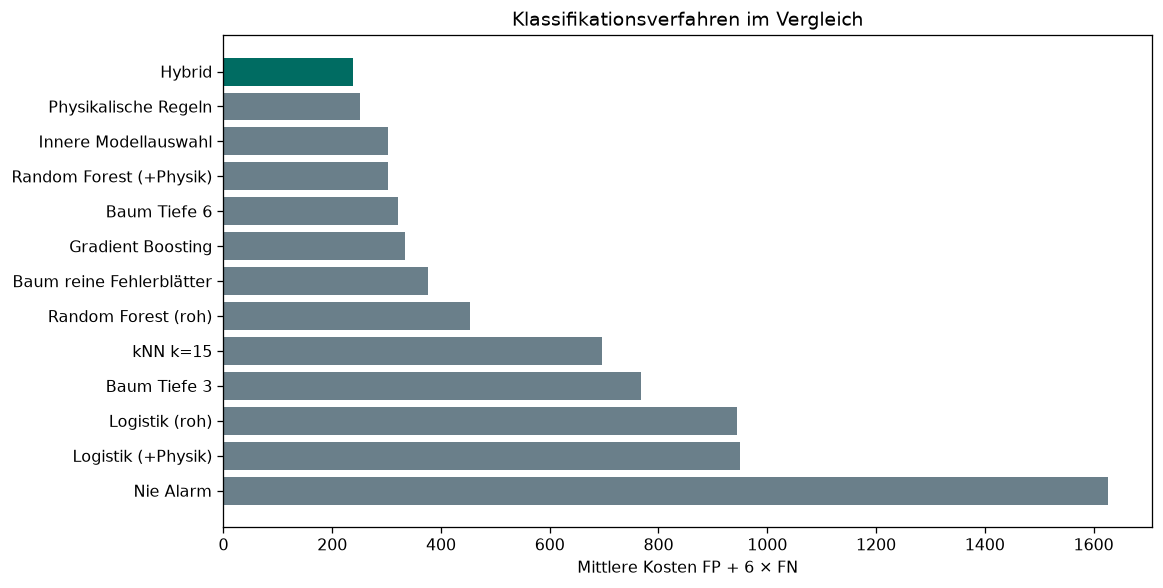

In [15]:
# V4, Zeile 1: Zeichnet das Ranking, wenn Matplotlib verfügbar ist.
if Figure is not None:
    # V4, Zeile 2: Erstellt eine 10 × 5 Zoll große Figur mit Platz für die Modellnamen.
    fig = Figure(figsize=(10, 5), layout="constrained")
    # V4, Zeile 3: Legt eine Zeichenfläche für das Balkendiagramm an.
    ax = fig.subplots()
    # V4, Zeile 4: Hebt den Hybrid grün hervor und färbt alle anderen Balken grau.
    farben = ["#006C62" if name == "Hybrid" else "#6A7F8A" for name in vergleich.index]
    # V4, Zeile 5: Zeichnet für jedes Modell einen horizontalen Balken mit seiner mittleren Kostenhöhe.
    ax.barh(vergleich.index, vergleich["Kosten"], color=farben)
    # V4, Zeile 6: Dreht die Modellreihenfolge um, sodass das günstigste Modell oben steht.
    ax.invert_yaxis()
    # V4, Zeile 7: Beschriftet die Kostenachse mit der Aufgabenmetrik und benennt den Modellvergleich.
    ax.set(xlabel="Mittlere Kosten FP + 6 × FN", title="Klassifikationsverfahren im Vergleich")
    # V4, Zeile 8: Zeigt das fertige Kostenranking im Notebook.
    diagramm_anzeigen(fig)

Tk is supported natively when running with `--simple-prompt`; no event loop hook will be installed.


,Rohmerkmale,Mit Physik
Logistik,945.0,949.6
Random Forest,452.6,303.4


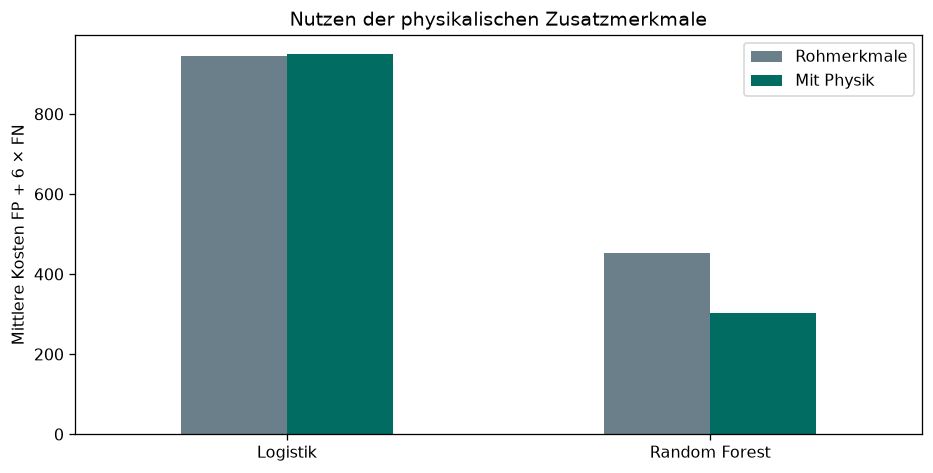

In [16]:
# V4, Zeile 1: Beginnt eine Vergleichstabelle für die beiden Varianten derselben Modellfamilie.
merkmalsvergleich = pd.DataFrame({
    # V4, Zeile 2: Entnimmt die mittleren Kosten der Logistik und des Random Forest, die nur Rohmerkmale nutzen.
    "Rohmerkmale": [vergleich.loc[f"{name} (roh)", "Kosten"] for name in ("Logistik", "Random Forest")],
    # V4, Zeile 3: Entnimmt die entsprechenden Kosten mit physikalischen Zusatzmerkmalen.
    "Mit Physik": [vergleich.loc[f"{name} (+Physik)", "Kosten"] for name in ("Logistik", "Random Forest")],
# V4, Zeile 4: Schließt die Tabelle und benennt ihre zwei Zeilen nach den Modellfamilien.
}, index=["Logistik", "Random Forest"])
# V4, Zeile 5: Zeigt die Kostentabelle auf eine Nachkommastelle gerundet.
display(merkmalsvergleich.round(1))
# V4, Zeile 6: Erstellt zusätzlich eine Grafik, wenn Matplotlib verfügbar ist.
if Figure is not None:
    # V4, Zeile 7: Erzeugt eine 8 × 4 Zoll große Figur.
    fig = Figure(figsize=(8, 4), layout="constrained")
    # V4, Zeile 8: Legt die Zeichenfläche für den direkten Merkmalsvergleich an.
    ax = fig.subplots()
    # V4, Zeile 9: Zeichnet pro Modellfamilie zwei Balken; Grau steht für Rohmerkmale und Grün für die Ergänzung um Physik.
    merkmalsvergleich.plot.bar(ax=ax, color=["#6A7F8A", "#006C62"], rot=0)
    # V4, Zeile 10: Beschriftet die y-Achse mit den mittleren Fehlerkosten und den Titel mit der untersuchten Merkmalswirkung.
    ax.set(ylabel="Mittlere Kosten FP + 6 × FN", title="Nutzen der physikalischen Zusatzmerkmale")
    # V4, Zeile 11: Zeigt die fertige Grafik im Notebook.
    diagramm_anzeigen(fig)

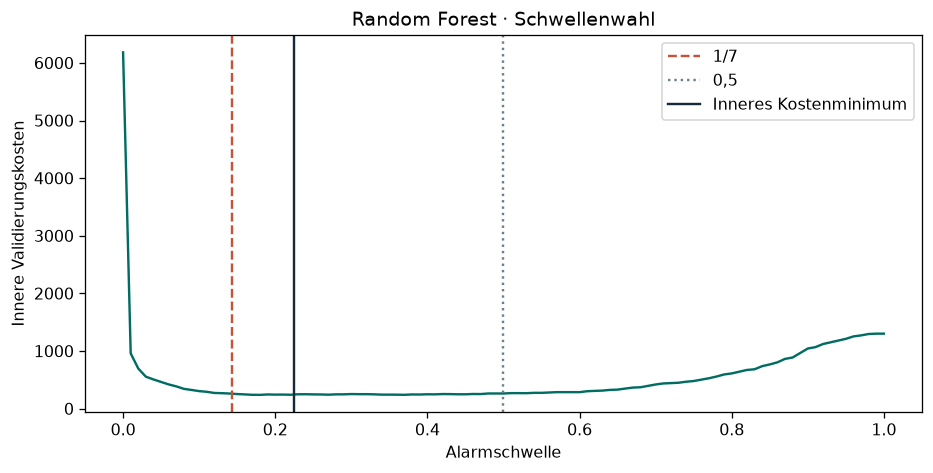

In [17]:
# Diese Scores stammen ausschließlich aus den inneren Prüffalten der ersten Trainingsfalte.
# V4, Zeile 2: Erzeugt 101 Schwellen zwischen 0 und 1 und ergänzt den theoretischen Wert 1/7 ohne doppelte Einträge.
schwellenraster = np.unique(np.r_[np.linspace(0, 1, 101), SCHWELLE])
# V4, Zeile 3: Berechnet für jede Schwelle die Kosten auf den gespeicherten inneren Validierungsscores.
trainingskosten = [kennzahlen(tuning_ziel, tuning_score >= t)["Kosten"] for t in schwellenraster]
# V4, Zeile 4: Bestimmt mit der exakten Schwellenfunktion die günstigste innere Schwelle; der zweite Rückgabewert wird verworfen.
beste_schwelle, _ = schwelle_waehlen(tuning_ziel, tuning_score)
# V4, Zeile 5: Zeichnet die Schwellenanalyse, wenn Matplotlib verfügbar ist.
if Figure is not None:
    # V4, Zeile 6: Erstellt dafür eine 8 × 4 Zoll große Figur.
    fig = Figure(figsize=(8, 4), layout="constrained")
    # V4, Zeile 7: Legt eine Zeichenfläche für die Kostenkurve an.
    ax = fig.subplots()
    # V4, Zeile 8: Verbindet die Schwellen und die zugehörigen inneren Kosten als grüne Linie.
    ax.plot(schwellenraster, trainingskosten, color="#006C62")
    # V4, Zeile 9: Markiert 1/7 durch eine orange gestrichelte senkrechte Linie.
    ax.axvline(SCHWELLE, color="#C65337", linestyle="--", label="1/7")
    # V4, Zeile 10: Markiert den üblichen Standardwert 0,5 durch eine graue gepunktete Linie.
    ax.axvline(.5, color="#6A7F8A", linestyle=":", label="0,5")
    # V4, Zeile 11: Prüft, ob das innere Kostenminimum eine endliche Schwelle besitzt.
    if np.isfinite(beste_schwelle):
        # V4, Zeile 12: Markiert diese endliche optimale Schwelle durch eine dunkle senkrechte Linie.
        ax.axvline(beste_schwelle, color="#152B3B", label="Inneres Kostenminimum")
    # V4, Zeile 13: Beschriftet x-Achse, innere Validierungskosten und Modellbezug.
    ax.set(xlabel="Alarmschwelle", ylabel="Innere Validierungskosten", title="Random Forest · Schwellenwahl")
    # V4, Zeile 14: Zeigt die Legende für die drei markierten Schwellen.
    ax.legend()
    # V4, Zeile 15: Zeigt die fertige Schwellenkurve im Notebook.
    diagramm_anzeigen(fig)

## 7 · Interpretation des Entscheidungsbaums und der Hybridregeln

Der kleine Entscheidungsbaum wurde auf der ersten äußeren Trainingsfalte gelernt. Seine Splits und Blätter zeigen die Merkmalsbeiträge in diesem Modell. Die Darstellung enthält alle Ebenen bis zur maximalen Tiefe 3. Die Klassenanteile sind Trainingsanteile. Die im Knoten angezeigte Klasse ist die häufigere Trainingsklasse. Der tatsächliche Alarm richtet sich nach dem Blattanteil und der darunter angegebenen, innerlich gewählten Schwelle. Anschließend werden die Hybridregeln auf allen beschrifteten Daten trainiert und separat dokumentiert.

Alarmschwelle dieses Baums aus innerer CV: 0.333


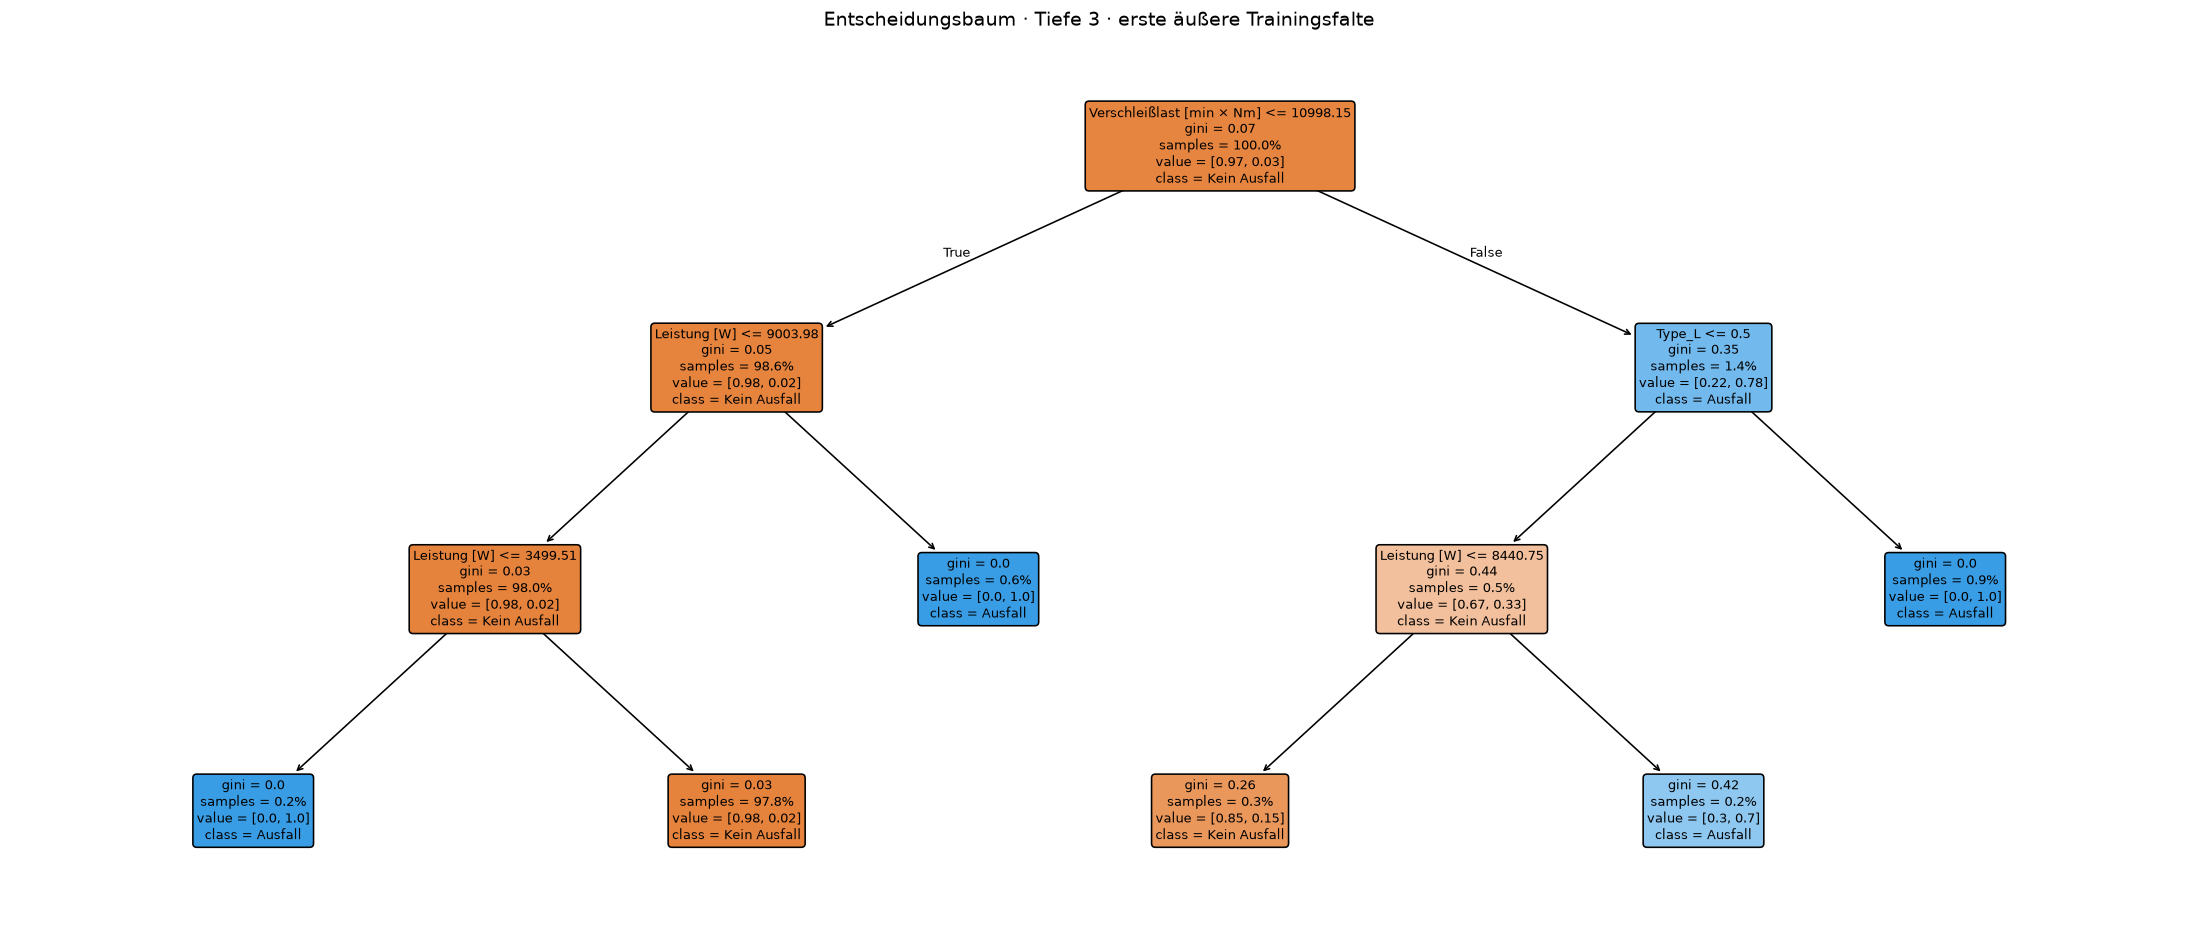

In [18]:
# V4, Zeile 1: Zeichnet den Interpretationsbaum, wenn Matplotlib verfügbar ist.
if Figure is not None:
    # V4, Zeile 2: Lädt einen Renderer, der den Baum auch ohne geöffnetes Grafikfenster zeichnen kann.
    from matplotlib.backends.backend_agg import FigureCanvasAgg

    # V4, Zeile 4: Erstellt eine breite 19 × 8 Zoll große Figur, damit die Baumknoten lesbar bleiben.
    fig = Figure(figsize=(19, 8), layout="constrained")
    # V4, Zeile 5: Verknüpft den Renderer mit der Figur, bevor scikit-learn die Knoten zeichnet.
    FigureCanvasAgg(fig)  # Stellt auch ohne grafisches Fenster einen Renderer für den Baum bereit.
    # V4, Zeile 6: Legt die Zeichenfläche für den Baum an.
    ax = fig.subplots()
    # V4, Zeile 7: Beginnt den Zeichenaufruf für den bereits trainierten kleinen Entscheidungsbaum.
    plot_tree(
        # V4, Zeile 8: Übergibt das Modell und die tatsächlichen Namen seiner Eingabemerkmale.
        kleiner_baum, feature_names=list(modell_merkmale.columns),
        # V4, Zeile 9: Benennt die Klassen, färbt die Knoten nach Mehrheitsklasse und verwendet abgerundete Kästen.
        class_names=["Kein Ausfall", "Ausfall"], filled=True, rounded=True,
        # V4, Zeile 10: Zeigt Fallanteile statt Fallzahlen und rundet dargestellte Zahlen auf zwei Dezimalstellen; Schriftgröße 8 hält den Baum kompakt.
        proportion=True, precision=2, fontsize=8, ax=ax,
    # V4, Zeile 11: Schließt den Aufruf zum Zeichnen des Baums ab.
    )
    # V4, Zeile 12: Kennzeichnet die Grafik als Baum der Tiefe 3 aus der ersten äußeren Trainingsfalte.
    ax.set_title("Entscheidungsbaum · Tiefe 3 · erste äußere Trainingsfalte")
    # V4, Zeile 13: Zeigt die fertige Baumgrafik im Notebook.
    diagramm_anzeigen(fig)
# V4, Zeile 14: Gibt die auf inneren Validierungsdaten gewählte Alarmschwelle dieses Baums mit drei Nachkommastellen aus.
print(f"Alarmschwelle dieses Baums aus innerer CV: {baum_schwelle:.3f}")

In [19]:
# Tatsächliche Pfade des ersten trainierten Regelbaums. Grenzwerte zur Darstellung gerundet.
# V4, Zeile 2: Definiert die Ausgabe von Trainingsblättern, die ausschließlich Ausfälle enthalten.
def fehlerblaetter(baum, spalten):
    # V4, Zeile 3: Greift auf die intern gespeicherte Baumstruktur zu.
    struktur = baum.tree_
    # V4, Zeile 4: Beginnt eine leere Liste der gefundenen Blattregeln.
    regeln = []

    # V4, Zeile 6: Definiert eine rekursive Hilfsfunktion, die einen Knoten samt bisherigem Entscheidungspfad besucht.
    def besuche(knoten, pfad):
        # V4, Zeile 7: Liest die Kennungen der beiden Kinder des aktuellen Knotens.
        links, rechts = struktur.children_left[knoten], struktur.children_right[knoten]
        # V4, Zeile 8: Erkennt ein Blatt daran, dass kein linkes Kind vorhanden ist.
        if links == -1:
            # V4, Zeile 9: Liest die Klassenhäufigkeiten beziehungsweise Klassenanteile des Blatts in der Reihenfolge 0, 1.
            anteile = struktur.value[knoten][0]
            # V4, Zeile 10: Prüft, ob im Blatt keine normalen Vorgänge und mindestens ein Ausfall liegen.
            if anteile[0] == 0 and anteile[1] > 0:
                # V4, Zeile 11: Speichert die Anzahl der Trainingsfälle und verbindet die Bedingungen des Pfads mit UND.
                regeln.append((int(struktur.n_node_samples[knoten]), " UND ".join(pfad)))
            # V4, Zeile 12: Beendet die Suche an diesem Blatt und kehrt zum übergeordneten Aufruf zurück.
            return
        # V4, Zeile 13: Übersetzt die interne Spaltennummer des Splits in den lesbaren Merkmalsnamen.
        merkmal = spalten[struktur.feature[knoten]]
        # V4, Zeile 14: Liest den tatsächlich gelernten Splitwert aus.
        grenze = struktur.threshold[knoten]
        # V4, Zeile 15: Besucht den linken Teilbaum mit der ergänzten <=-Bedingung; die Zahl wird nur zur Darstellung gerundet.
        besuche(links, [*pfad, f"{merkmal} <= {grenze:.2f}"])
        # V4, Zeile 16: Besucht den rechten Teilbaum mit der ergänzten >-Bedingung.
        besuche(rechts, [*pfad, f"{merkmal} > {grenze:.2f}"])

    # V4, Zeile 18: Startet die rekursive Suche an der Wurzel, deren Knotennummer 0 ist.
    besuche(0, [])
    # V4, Zeile 19: Sortiert die Blattregeln nach Fallzahl absteigend und gibt sie als Tabelle zurück.
    return pd.DataFrame(sorted(regeln, reverse=True), columns=["Trainingsfälle im Blatt", "Pfad"])

# V4, Zeile 21: Kennzeichnet ausdrücklich, dass die angezeigten Splitwerte nur gerundet dargestellt sind.
print("Die folgenden Grenzwerte sind zur Darstellung auf zwei Dezimalstellen gerundet.")
# V4, Zeile 22: Zeigt die reinen Fehlerblätter des gespeicherten Trainingsbaums mit den passenden Merkmalsnamen.
display(fehlerblaetter(regelbaum, list(modell_merkmale.columns)))

Die folgenden Grenzwerte sind zur Darstellung auf zwei Dezimalstellen gerundet.


,Trainingsfälle im Blatt,Pfad
0,60,Verschleißlast [min × Nm] <= 10998.15 UND Leis...
1,59,Verschleißlast [min × Nm] > 10998.15 UND Type_...
2,38,Verschleißlast [min × Nm] <= 10998.15 UND Leis...
3,13,Verschleißlast [min × Nm] <= 10998.15 UND Leis...


### Verbleibende Ausfälle und wirtschaftliche Entscheidung

Die folgende Beschreibung basiert auf den äußeren Prüfvorhersagen des ersten Seeds. Sie zeigt die Ausfallquote der vom Regelkern freigegebenen Vorgänge nach Standzeit. Eine Quote unter 1/7 spricht bei den vorgegebenen Kosten gegen einen pauschalen Alarm für die ganze Gruppe. Aus einer Gruppenquote folgt jedoch keine Aussage darüber, ob feinere Merkmale noch Vorhersageinformation enthalten. Deshalb wird die Verschleißstufe separat anhand ihrer Prüfkosten bewertet.

Vom Regelkern übersehene Ausfälle: 42


,Vorgänge,Ausfälle,Quote [%]
Standzeitgruppe,,,
"[-inf, 200.0)",7202,6,0.08
"[200.0, 220.0)",466,23,4.94
"[220.0, inf)",103,13,12.62


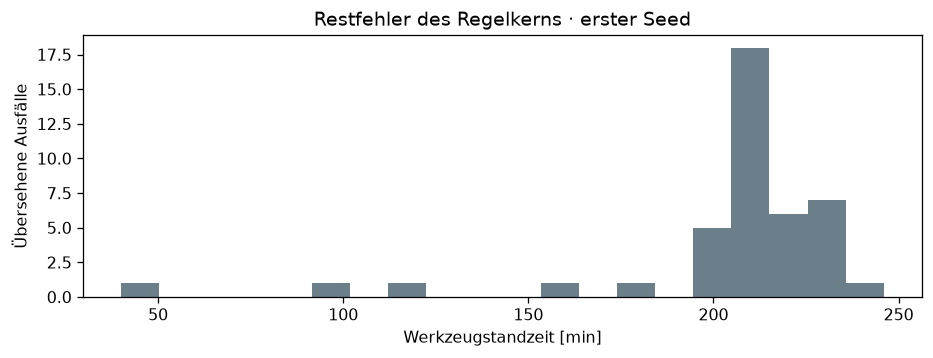

In [20]:
# V4, Zeile 1: Nimmt die gespeicherten Prüfvorhersagen der ersten Seed-Aufteilung für die Restfehleranalyse.
diagnose = pruefdiagnosen[0]
# V4, Zeile 2: Kopiert die Vorgänge, bei denen der physikalische Regelkern keinen Alarm auslöste.
rest = diagnose.loc[diagnose["Regelalarm"] == 0].copy()
# V4, Zeile 3: Teilt die Standzeit in unter 200, 200 bis unter 220 und ab 220 Minuten ein; die rechte Intervallgrenze gehört jeweils zur nächsten Gruppe.
rest["Standzeitgruppe"] = pd.cut(rest["Standzeit"], bins=[-np.inf, 200, 220, np.inf], right=False)
# V4, Zeile 4: Zählt je tatsächlich besetzter Standzeitgruppe alle Vorgänge und die darin enthaltenen Ausfälle.
band = rest.groupby("Standzeitgruppe", observed=True)["Ausfall"].agg(Vorgänge="size", Ausfälle="sum")
# V4, Zeile 5: Berechnet die Ausfallquote jeder Gruppe als Prozentwert.
band["Quote [%]"] = 100 * band["Ausfälle"] / band["Vorgänge"]
# V4, Zeile 6: Zeigt die gruppierte Restfehlerauswertung mit zwei Nachkommastellen.
display(band.round(2))
# V4, Zeile 7: Gibt die Anzahl tatsächlicher Ausfälle aus, die der Regelkern im ersten Durchlauf freigegeben hat.
print("Vom Regelkern übersehene Ausfälle:", int(rest["Ausfall"].sum()))
# V4, Zeile 8: Erstellt zusätzlich ein Histogramm, wenn Matplotlib verfügbar ist.
if Figure is not None:
    # V4, Zeile 9: Erzeugt eine 8 × 3 Zoll große Figur.
    fig = Figure(figsize=(8, 3), layout="constrained")
    # V4, Zeile 10: Legt eine Zeichenfläche für die Restfehlerverteilung an.
    ax = fig.subplots()
    # V4, Zeile 11: Zeigt nur die Standzeiten tatsächlich ausgefallener, vom Regelkern freigegebener Vorgänge in 20 Intervallen.
    ax.hist(rest.loc[rest["Ausfall"] == 1, "Standzeit"], bins=20, color="#6A7F8A")
    # V4, Zeile 12: Beschriftet die Standzeit, die Anzahl übersehener Ausfälle und den Bezug zur ersten Aufteilung.
    ax.set(xlabel="Werkzeugstandzeit [min]", ylabel="Übersehene Ausfälle", title="Restfehler des Regelkerns · erster Seed")
    # V4, Zeile 13: Zeigt das fertige Restfehlerhistogramm im Notebook.
    diagramm_anzeigen(fig)

In [21]:
# V4, Zeile 1: Trainiert den festgelegten Hybrid für die Challenge auf allen beschrifteten Modellierungsdaten.
finales_modell = hybrid_trainieren(X, y)
# V4, Zeile 2: Entpackt die Regelgrenzen und den Verschleißbeginn; das Logistikobjekt wird für diese Tabelle nicht benötigt.
(tief, hoch, delta, rpm, lastgrenzen), beginn, _ = finales_modell
# V4, Zeile 3: Beginnt die Liste der gelernten Grenzen, die für die Interpretation ausgegeben werden.
grenzen_anzeigen = [
    # V4, Zeile 4: Fügt die untere und die obere Leistungsgrenze mit Watt als Einheit hinzu.
    ("Leistung unter [W]", tief), ("Leistung über [W]", hoch),
    # V4, Zeile 5: Fügt beide gemeinsam zu erfüllenden Kühlungsgrenzen mit ihren jeweiligen Einheiten hinzu.
    ("Kühlung: Temperaturabstand unter [K]", delta), ("Kühlung: zugleich Drehzahl unter [U/min]", rpm),
    # V4, Zeile 6: Erzeugt für L, M und H jeweils eine Tabellenzeile mit der passenden Belastungsgrenze und übernimmt alle Zeilen in die Liste.
    *[(f"Belastung Typ {typ} über [min × Nm]", lastgrenzen[code]) for typ, code in TYP.items()],
    # V4, Zeile 7: Fügt den aus den Daten gelernten Beginn des Verschleißeffekts in Minuten hinzu.
    ("Beginn des Verschleißeffekts [min]", beginn),
# V4, Zeile 8: Schließt die Liste der gelernten Grenzwerte ab.
]
# V4, Zeile 9: Wandelt die Liste in eine beschriftete Tabelle um und zeigt sie mit zwei Nachkommastellen.
display(pd.DataFrame(grenzen_anzeigen, columns=["Merkmal", "Gelernte Grenze"]).round(2))

,Merkmal,Gelernte Grenze
0,Leistung unter [W],3500.0
1,Leistung über [W],9000.0
2,Kühlung: Temperaturabstand unter [K],8.6
3,Kühlung: zugleich Drehzahl unter [U/min],1380.0
4,Belastung Typ L über [min × Nm],11000.0
5,Belastung Typ M über [min × Nm],12000.0
6,Belastung Typ H über [min × Nm],13000.0
7,Beginn des Verschleißeffekts [min],200.0


## 8 · Challenge-Prognose und Kostenschätzung

Nach Abschluss des Trainings wird challenge.csv eingelesen. Der Export enthält ausschließlich die Spalte Machine failure und hält die Eingabereihenfolge ein. Die erwarteten Gesamtkosten ergeben sich aus den mittleren Validierungskosten je Vorgang, multipliziert mit der Zahl der Challenge-Vorgänge. Die Hochrechnung setzt vergleichbare Vorgänge voraus.

In [22]:
# V4, Zeile 1: Prüft den Gruppennamen auf erlaubte Zeichen und darauf, dass er nicht nur aus Leerzeichen besteht.
if not re.fullmatch(r"[\w -]+", GRUPPENNAME) or not GRUPPENNAME.strip():
    # V4, Zeile 2: Bricht mit einer Eingabeaufforderung ab, wenn der Name ungültig ist.
    raise ValueError("Bitte einen gültigen Gruppennamen in der ersten Zelle eintragen.")
# V4, Zeile 3: Liest erst jetzt die unbeschriftete Challenge-Datei mit derselben Datenprüfung ein.
challenge = csv_lesen(DATENORDNER / "challenge.csv")
# V4, Zeile 4: Berechnet mit dem auf allen beschrifteten Daten trainierten Hybrid die Challenge-Klassen; die separate Regelvorhersage wird verworfen.
_, prognosen = vorhersagen(challenge, finales_modell)
# V4, Zeile 5: Erstellt den Ausgabeordner einschließlich fehlender übergeordneter Ordner, falls nötig.
AUSGABEORDNER.mkdir(parents=True, exist_ok=True)
# V4, Zeile 6: Baut den geforderten Dateinamen aus festem Präfix, Gruppenname und .csv auf.
datei = AUSGABEORDNER / f"challenge_prediction_{GRUPPENNAME}.csv"
# V4, Zeile 7: Schreibt genau die Zielspalte ohne zusätzliche Indexspalte und mit einheitlichem Zeilenumbruch.
pd.DataFrame({TARGET: prognosen}).to_csv(datei, index=False, lineterminator="\n")
# V4, Zeile 8: Liest die gerade erzeugte Datei zur Kontrolle erneut ein.
kontrolle = pd.read_csv(datei)
# V4, Zeile 9: Prüft, ob Spaltenschema und Klassenfolge exakt mit der berechneten Prognose übereinstimmen.
assert list(kontrolle.columns) == [TARGET] and np.array_equal(kontrolle[TARGET], prognosen)

# V4, Zeile 11: Berechnet die mittleren Hybridkosten aus den fünf vollständigen Validierungswiederholungen.
kosten_mittel = cv.loc[cv["Modell"] == "Hybrid", "Kosten"].mean()
# V4, Zeile 12: Skaliert diese Kosten pro beschriftetem Vorgang auf die Anzahl der Challenge-Vorgänge.
erwartete_kosten = kosten_mittel / len(y) * len(challenge)
# V4, Zeile 13: Zeigt Pfad, Anzahl der Vorhersagen und Summe der vorhergesagten Ausfälle an.
print(f"{datei} | {len(prognosen)} Vorhersagen | {prognosen.sum()} Alarme")
# V4, Zeile 14: Gibt die erwarteten Challenge-Kosten mit einer Nachkommastelle aus.
print(f"Geschätzte Challenge-Kosten: {erwartete_kosten:.1f}")

results\challenge_prediction_GRUPPENNAME.csv | 2000 Vorhersagen | 63 Alarme
Geschätzte Challenge-Kosten: 59.4


## Schlussfolgerungen

Die Zusammenfassung wird aus dem ausgeführten Modellvergleich erzeugt. Der Hybrid bleibt der festgelegte Abgabekandidat aus V2. Die Vorlesungsmodelle liefern einen nachvollziehbaren Vergleich und der kleine Baum eine zusätzliche Interpretation. Eine spätere Wahl anhand der äußeren Rangliste wäre ein weiterer Entwicklungsschritt auf derselben Kohorte.

In [23]:
# V4, Zeile 1: Bestimmt den günstigsten Einzelkandidaten aus der bereits sortierten Tabelle; Baseline und innere Auswahlstrategie werden für diese Bezeichnung ausgeklammert.
bestes_einzelmodell = vergleich.drop(index=["Nie Alarm", "Innere Modellauswahl"]).index[0]
# V4, Zeile 2: Gibt den Namen dieses Kandidaten und seine mittleren Kosten mit einer Nachkommastelle aus.
print(f"Niedrigste mittlere Kosten im Vergleich: {bestes_einzelmodell} ({vergleich.loc[bestes_einzelmodell, 'Kosten']:.1f})")
# V4, Zeile 3: Stellt die mittleren Kosten des Hybrids und des reinen Regelkerns direkt gegenüber.
print(f"Hybrid: {vergleich.loc['Hybrid', 'Kosten']:.1f} | Regelkern: {vergleich.loc['Physikalische Regeln', 'Kosten']:.1f}")
# V4, Zeile 4: Fasst die Anzahl der Challenge-Vorgänge, die ausgelösten Alarme und die geschätzten Gesamtkosten zusammen.
print(f"Challenge: {len(prognosen)} Vorgänge, {prognosen.sum()} Alarme, geschätzte Kosten {erwartete_kosten:.1f}")

Niedrigste mittlere Kosten im Vergleich: Hybrid (237.6)
Hybrid: 237.6 | Regelkern: 252.0
Challenge: 2000 Vorgänge, 63 Alarme, geschätzte Kosten 59.4


## Empfehlungen zur Prozessüberwachung

Leistung, Temperaturabstand und Werkzeugbelastung sollten als berechnete Prozessgrößen mit Messwert und Alarmgrenze protokolliert werden. Im Schattenbetrieb sind die tatsächlich verfügbare Vorwarnzeit, Inspektionsdauer und bestätigte Befunde zu erfassen. Daraus lassen sich später Alarmkosten und Einsatzschwelle anpassen.

Werkzeugwechsel im hohen Standzeitbereich sollten anhand dokumentierter Inspektionsbefunde und Kosten geprüft werden. Die vorliegenden Einzelvorgänge erlauben eine Klassifikation. Für Aussagen über Verschleißverläufe werden Zeitstempel und Werkzeugzyklus-IDs benötigt.

## Quellen, Eigenbeiträge und Hilfsmittel

- Aufgabenstellung Classification, TH Mannheim, WiSe 2026/27. Kostenfunktion, Datengrundlage und Vorhersageformat.
- A. Samberg, Data Mining – Classification Part 1 und Part 2. Bäume, Merkmale, Kennzahlen und Kreuzvalidierung.
- Bereitgestellte Referenzgruppe Data Desperados, SoSe 2026: Predictive_Maintenance_Data_Desperados_Final.ipynb, Pitch_Data_Desperados.pdf und Langpräsentation_Data_Desperados.pdf. Anregung für Aufbau, physikalische Darstellungen, Baumregeln und Roh-/Physikvergleich. Die Referenzunterlagen enthalten eigene Zahlen und Leistungserklärungen. Die vorliegenden Ergebnisse werden aus den aktuellen Eingabedaten neu berechnet.

Die Gruppe stellte Aufgabenstellung und Fachunterlagen bereit, diskutierte Kosten und Nachvollziehbarkeit und gab den Vorlesungsbezug und die zusätzliche Referenzversion vor. OpenAI Codex, OpenAI, unterstützte Codeentwurf, Ausführung, Kommentierung und Formulierung. Die Gruppenmitglieder ergänzen vor Abgabe ihre tatsächlich vorgenommenen fachlichen Prüfungen und weiteren Eigenbeiträge.